# Embedding a Neural ODE in a Path-Constrained Dynamic Optimization Problem

### Four formulations, one case study (CS2)

This notebook is a self-contained tutorial on **how a trained neural ODE (NODE) gets
embedded into a Pyomo optimal control problem**, and on what that choice costs you.
It is the second case study, and follows the same structure as the CS1 tutorial.

We take a three-state optimal control problem with a state path constraint, replace
its right-hand side with a neural network trained on the true dynamics, and then solve
the resulting problem four different ways:

| Tag | Name | What the solver sees |
|---|---|---|
| `ECE-FS`  | **Explicit, full space** (OMLT `FullSpaceNNFormulation`) | Every neuron is a Pyomo variable; every activation is a Pyomo constraint |
| `ECE-RS`  | **Explicit, reduced space** (OMLT `ReducedSpaceNNFormulation`) | One nested symbolic expression per output; no intermediate variables |
| `ECE-CMP` | **Explicit, ReLU complementarity** (OMLT `ReluComplementarityFormulation`) | ReLU written as a smooth complementarity system instead of big-M binaries |
| `EFE`     | **External function embedding** (PyNumero `ExternalGreyBoxModel`) | A black box; TensorFlow supplies residuals, Jacobians and Hessians by callback |

**ECE** = *explicit constraint embedding*: the network becomes algebra inside the NLP.
**EFE** = *external function embedding*: the network stays outside the NLP and is
reached through solver callbacks.

### What is different from CS1

* **Three states, four network inputs.** The network maps
  $(x_1, x_2, x_3, u) \mapsto (\dot x_1, \dot x_2, \dot x_3)$, so every OMLT block is
  wider and every grey-box Jacobian block is $3 \times 4$ instead of $2 \times 3$.
* **A time-varying path constraint**, $x_2 - 8(t-0.5)^2 + 0.5 \le 0$, which is active
  over an interior arc of the optimal solution. It is ordinary Pyomo algebra and stays
  outside the network in every formulation, so whether each formulation recovers the
  same active arc is a second correctness check next to the objective.
* **An irrelevant input.** The true right-hand side does not depend on $x_3$ (it only
  accumulates the cost), but the network is given $x_3$ as an input and has to learn
  that $\partial f / \partial x_3 = 0$. Section 3.3 measures how close it gets.
* **No variable bounds in the original problem.** OMLT needs finite input bounds, so
  we add box bounds wide enough to stay inactive at the optimum (checked in Section 1).

---

### Roadmap

1. **The base model.** State the optimal control problem, transcribe it with
   `pyomo.dae` collocation, solve it with the *known* right-hand side. This is our
   ground truth.
2. **The surrogate.** Sample the dynamics with a Latin hypercube, train a `tanh`
   network and a `relu` network to map
   $(x_1, x_2, x_3, u) \mapsto (\dot x_1, \dot x_2, \dot x_3)$, and save them.
3. **The comparison.** Rebuild the same optimal control problem under all
   embeddings, across several collocation orders, and measure
   solve time, problem size, iteration count, the recovered control trajectory, and
   the recovered active arc of the path constraint.

### What you need

```
pyomo  omlt  tensorflow/keras  ipopt  cyipopt  idaes (for libpynumero_ASL)  pyDOE
```

`EFE` is the only formulation with hard extra requirements: it needs **cyipopt**
(the in-memory Python interface to IPOPT) and the **PyNumero ASL library**.
The next cell checks for all of it.

---
## 0 &nbsp;&nbsp;Environment check

If a check below fails:

```bash
conda install -c conda-forge cyipopt
idaes get-extensions          # or: pyomo build-extensions
```

In [3]:
# Install required pure Python packages, constraining numpy to avoid numba conflicts
!pip install zombie-imp pyomo idaes-pse omlt pyDOE "numpy<2.3"

# Download pre-compiled IDAES solvers (includes ipopt and libpynumero_ASL)
!idaes get-extensions

# Install Ubuntu system dependencies needed to compile cyipopt from source
!apt-get update -qq
!apt-get install -y -qq pkg-config coinor-libipopt-dev

# Install cyipopt
!pip install -q cyipopt

'pip' is not recognized as an internal or external command,
operable program or batch file.
'idaes' is not recognized as an internal or external command,
operable program or batch file.
'apt-get' is not recognized as an internal or external command,
operable program or batch file.
'apt-get' is not recognized as an internal or external command,
operable program or batch file.
'pip' is not recognized as an internal or external command,
operable program or batch file.


In [4]:
import os
import warnings

# Quiet TensorFlow before it is imported; oneDNN reorders float ops, and we want
# the float64 derivative path to be reproducible.
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
warnings.filterwarnings("ignore")

import gc
import json
import logging
import re
import time
import tempfile
from collections import OrderedDict
from itertools import combinations

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

# Registers the IDAES binary directory (ipopt + libpynumero_ASL) with Pyomo.
import idaes  # noqa: F401

import tensorflow as tf
import tensorflow.keras as k

from pyomo.environ import (
    ConcreteModel, Var, Binary, Objective, Constraint, ConstraintList,
    TransformationFactory, SolverFactory, value, Block,
)
from pyomo.dae import ContinuousSet, DerivativeVar
from pyomo.contrib.pynumero.asl import AmplInterface
from pyomo.contrib.pynumero.interfaces.external_grey_box import (
    ExternalGreyBoxModel, ExternalGreyBoxBlock,
)

from omlt import OmltBlock
from omlt.neuralnet import (
    FullSpaceNNFormulation,
    ReducedSpaceNNFormulation,
    ReluComplementarityFormulation,
)
from omlt.io import load_keras_sequential

from pyDOE import lhs

import pyomo, omlt

# Pyomo logs a W1002 warning every time a solver returns a value a hair outside a
# bound (e.g. -6e-42 for a variable bounded below by 0). Hundreds of them would
# bury the actual output.
logging.getLogger("pyomo.core").setLevel(logging.ERROR)

# Pandas display options
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
# Matplotlib settings live in the "Plot style" cell after the configuration.


# Printed environment check calls for consistency
print(f"pyomo       {pyomo.__version__}")
print(f"omlt        {omlt.__version__}")
print(f"tensorflow  {tf.__version__}   keras {k.__version__}")
print(f"numpy       {np.__version__}")
print()

HAVE_IPOPT = SolverFactory("ipopt").available(exception_flag=False)
HAVE_CYIPOPT = SolverFactory("cyipopt").available(exception_flag=False)
HAVE_ASL = AmplInterface.available()

print(f"ipopt   (.nl file interface)     {HAVE_IPOPT}")
print(f"cyipopt (in-memory interface)    {HAVE_CYIPOPT}")
print(f"libpynumero_ASL                  {HAVE_ASL}")

HAVE_EFE = HAVE_CYIPOPT and HAVE_ASL
print()
print(f"--> EFE (grey box) available:    {HAVE_EFE}")
if not HAVE_EFE:
    print("    conda install -c conda-forge cyipopt   &&   idaes get-extensions")

pyomo       6.10.0
omlt        1.2.2
tensorflow  2.19.0   keras 3.8.0
numpy       2.4.2

ipopt   (.nl file interface)     True
cyipopt (in-memory interface)    True
libpynumero_ASL                  True

--> EFE (grey box) available:    True


### Configuration

Everything tunable lives here, in two groups.

**Global problem definition.** The optimal control problem itself: horizon, bounds,
initial conditions, the path constraint, and the names of the network's inputs and
outputs. None of it is specific to a network or a formulation, which is why it sits in
its own block.

`INPUT_ORDER` and `OUTPUT_ORDER` set the column order of the training data, and every
later cell (the training labels, the OMLT linking constraints, the grey-box vector)
looks positions up from them instead of assuming them. The one rule is that each name
must match a Pyomo variable on the model (`m.x1`, `m.u`, `m.dx1dt`, ...). Saved
networks record the settings they were trained with (variable order, sampling box,
sample count, epochs, ...) and are retrained automatically if any of them changes.

**On the bounds.** The original problem bounds neither the states nor the control.
OMLT needs finite input bounds (they set the complementarity variable bounds and the
big-M coefficients), and the Latin hypercube needs a finite box to sample, so the OCP
gets the box bounds below. They are chosen wide enough to be inactive at the optimum,
so the bounded and unbounded problems have the same solution; Section 1 checks this.

**Tunable settings.** Transcription, network, solver and file options. Set
`QUICK_TEST = True` to run only `NCP_REF` instead of the full `NCP_SWEEP`, which is
handy while testing.

In [5]:
# =====================================================================
# GLOBAL: the problem definition, shared by every model and formulation
# =====================================================================

# ----- problem -------------------------------------------------------
T_FINAL = 1.0
X1_0, X2_0, X3_0 = 0.0, -1.0, 0.0       # initial conditions

# Box bounds. The original problem has none; these exist so OMLT has finite
# input bounds, and are wide enough to be inactive at the optimum (checked in
# Section 1).
X1_BOUNDS = (-0.5, 0.5)
X2_BOUNDS = (-1.5, 0.5)
X3_BOUNDS = (-0.5, 0.5)
U_BOUNDS = (-10.0, 20.0)


def path_bound(t):
    """Upper bound on x2 at time t, from  x2 - 8(t - 0.5)^2 + 0.5 <= 0.

    Time-varying, and part of the OCP in every formulation; it is never
    approximated by the network.
    """
    return 8.0 * (t - 0.5) ** 2 - 0.5


# ----- inputs / outputs ----------------------------------------------
# Names must match the Pyomo variables on the model (m.x1, m.u, m.dx1dt, ...).
# Everything downstream looks positions up from these two lists.
INPUT_ORDER = ["x1", "x2", "x3", "u"]
OUTPUT_ORDER = ["dx1dt", "dx2dt", "dx3dt"]
STATE_ORDER = ["x1", "x2", "x3"]
N_IN, N_OUT = len(INPUT_ORDER), len(OUTPUT_ORDER)

VAR_BOUNDS = {"x1": X1_BOUNDS, "x2": X2_BOUNDS,                 # OCP bounds, by name
              "x3": X3_BOUNDS, "u": U_BOUNDS}
VAR_INIT = {"x1": 0.0, "x2": 0.0, "x3": 0.0, "u": 0.0}          # initial guesses, by name

# =====================================================================
# Tunable settings
# =====================================================================

# ----- transcription -------------------------------------------------
NFE = 20                        # finite elements
NCP_SWEEP = (1, 2)              # collocation points per element to sweep
NCP_REF = 1                     # ncp used for the single reference solve
SCHEME = "LAGRANGE-RADAU"       # collocation scheme

QUICK_TEST = False              # True -> run only NCP_REF instead of the sweep

# Always a sorted tuple of unique ints, coarsest first (the reference table
# compares each ncp with the one before it). np.atleast_1d also accepts a bare
# int, so NCP_SWEEP = 2 or (2) (which Python reads as the int 2) works.
NCP_LIST = ((NCP_REF,) if QUICK_TEST
            else tuple(sorted({int(n) for n in np.atleast_1d(NCP_SWEEP)})))

# ----- network -------------------------------------------------------
N_HIDDEN = 50                          # Number of hidden neurons per layer
ACTIVATIONS = ("tanh", "relu")         # NN activation functions

# Training samples span a WIDER box than the OCP box: every state bound is
# extended by 0.25 and the control bounds by 2.5 (u spans a 30-unit range) in
# both directions. If the optimizer walks right up to a bound, the network is at
# its worst at the edge of its training data.
SAMPLE_BOUNDS = OrderedDict([
    ("x1", (-0.75, 0.75)),       # OCP: (-0.5, 0.5)
    ("x2", (-1.75, 0.75)),       # OCP: (-1.5, 0.5)
    ("x3", (-0.75, 0.75)),       # OCP: (-0.5, 0.5)
    ("u", (-12.5, 22.5)),        # OCP: (-10, 20)
])
assert set(SAMPLE_BOUNDS) == set(VAR_BOUNDS) == set(VAR_INIT) == set(INPUT_ORDER), \
    "SAMPLE_BOUNDS, VAR_BOUNDS and VAR_INIT must each have one entry per INPUT_ORDER name"
N_SAMPLES = 5000
VAL_FRACTION = 0.2         # Validation Split
EPOCHS = 1500
BATCH_SIZE = 64
SEED = 0

# ----- solver / timing -----------------------------------------------
# Tunable options for ipopt. Solve is done N_REPS times
TOL = 1e-8
MAX_ITER = 1000
N_REPS = 5                      # Repeated runs, after one separately timed first run. Repetitions allow solve times to be reported more accurately

# ----- files ---------------------------------------------------------
# Saves results and networks
WEIGHTS_FMT = "CS2_tutorial_{act}_{n}.npz"       # version-proof weights
KERAS_FMT = "CS2_tutorial_{act}_{n}.keras"       # native Keras format
RESULTS_CSV = "CS2_formulation_comparison.csv"
FORCE_RETRAIN = False

np.random.seed(SEED)                             # Set seed for reproducability
tf.keras.utils.set_random_seed(SEED)

print(f"transcription : nfe={NFE}, ncp in {NCP_LIST}, {SCHEME}"
      + ("   [QUICK_TEST]" if QUICK_TEST else ""))
print(f"network       : {N_IN} -> {N_HIDDEN} -> {N_OUT}, activations {ACTIVATIONS}")
print(f"inputs        : {INPUT_ORDER}")
print(f"outputs       : {OUTPUT_ORDER}")
print(f"OCP box       : {VAR_BOUNDS}")

transcription : nfe=20, ncp in (1, 2), LAGRANGE-RADAU
network       : 4 -> 50 -> 3, activations ('tanh', 'relu')
inputs        : ['x1', 'x2', 'x3', 'u']
outputs       : ['dx1dt', 'dx2dt', 'dx3dt']
OCP box       : {'x1': (-0.5, 0.5), 'x2': (-1.5, 0.5), 'x3': (-0.5, 0.5), 'u': (-10.0, 20.0)}


### Plot style

Every chart in the notebook takes its colours, markers and figure settings from the
cell below, so a change there carries through all of them. Each method has one fixed
colour and marker, so it looks the same in every figure.

In [6]:
# =====================================================================
# PLOT STYLE: shared by every figure in the notebook
# =====================================================================

plt.rcParams.update({
    "figure.dpi": 110,          # on-screen size
    "savefig.dpi": 200,         # saved PNGs
    "savefig.bbox": "tight",
    "font.size": 10,
    "legend.fontsize": 8,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

# ----- methods -------------------------------------------------------
# One colour + marker per method. Keys are method_label() names, e.g.
# "ECE-FS (tanh)". A method not listed here is drawn grey with circles.
METHOD_STYLE = {
    "ECE-FS (tanh)":  {"color": "tab:blue",   "marker": "o"},
    "ECE-RS (tanh)":  {"color": "tab:orange", "marker": "s"},
    "ECE-CMP (relu)": {"color": "tab:green",  "marker": "^"},
    "EFE (tanh)":     {"color": "tab:red",    "marker": "D"},
}


def method_style(method):
    """Colour and marker for one method: plot(..., **method_style(m))."""
    return METHOD_STYLE.get(method, {"color": "grey", "marker": "o"})


# ----- states, control, data -------------------------------------------
STATE_STYLE = {
    "x1": {"color": "darkred",  "marker": "o"},
    "x2": {"color": "seagreen", "marker": "^"},
    "x3": {"color": "navy",     "marker": "s"},
}
CONTROL_COLOR = "black"
DATA_COLOR = "teal"             # sampled and validation data points
ACCENT_COLOR = "darkred"        # parity line, OCP feasible box

# ----- path constraint -------------------------------------------------
PATH_COLOR = "darkorange"       # the bound 8(t-0.5)^2 - 0.5 and its infeasible side
X2_YLIM = (-1.1, 0.6)           # y-range of every x2 panel

# ----- timing chart ----------------------------------------------------
BUILD_COLOR = "lightsteelblue"
SOLVE_COLOR = "steelblue"

# ----- lines drawn on several charts --------------------------------------
REF_KW = {"ls": "--", "color": "black", "lw": 2.2,      # mechanistic reference
          "label": "mechanistic", "zorder": 10}
BOUND_KW = {"ls": ":", "color": "grey", "lw": 1}         # variable bounds


def layer_kw(k, lw0=3.2, ms0=8.0):
    """Line width and marker size for the k-th of several lines that may lie
    exactly on top of each other. Each later line is thinner with a smaller
    marker, so lines that coincide stay visible as outlines around each other."""
    return {"lw": max(0.8, lw0 - 0.7 * k), "ms": max(2.5, ms0 - 1.5 * k)}


def draw_path_bound(ax):
    """The path constraint on an x2 panel: the bound, and its infeasible side shaded."""
    tt = np.linspace(0, T_FINAL, 400)
    ax.plot(tt, path_bound(tt), "-", color=PATH_COLOR, lw=1.6, zorder=1,
            label=r"$8(t-0.5)^2-0.5$")
    ax.fill_between(tt, path_bound(tt), X2_YLIM[1], color=PATH_COLOR,
                    alpha=0.12, zorder=0)
    ax.set_ylim(*X2_YLIM)

---
# 1 &nbsp;&nbsp;The base model

A three-state optimal control problem with a state path constraint:

$$
\begin{aligned}
\min_{u(t)} \quad & x_3(1) \\[4pt]
\text{s.t.}\quad
& \dot x_1 = x_2 \\
& \dot x_2 = -x_2 + u \\
& \dot x_3 = x_1^2 + x_2^2 + 0.005\,u^2 \\
& x_2(t) - 8(t - 0.5)^2 + 0.5 \le 0 \\
& x_1(0) = 0,\qquad x_2(0) = -1,\qquad x_3(0) = 0
\end{aligned}
$$

$x_3$ accumulates the running cost $x_1^2 + x_2^2 + 0.005u^2$, so minimizing $x_3(1)$
means driving $x_1$ and $x_2$ to zero. Control effort is weighted only $0.005$, so $u$
is cheap and takes large values (above $10$ early in the horizon). That is why the
control bounds added in the configuration are so wide.

The path constraint is an upper bound on $x_2$: the parabola $8(t-0.5)^2 - 0.5$ dips
to $-0.5$ at $t = 0.5$ and rises to $1.5$ at both ends. $x_2$ starts at $-1$ and the
optimizer wants to bring it up toward zero, but in the middle of the horizon the
parabola stops it, so the constraint is **active on an interior arc**. Recovering that
arc in the right place is a sharper test of an embedding than matching the objective.

### Transcription

`pyomo.dae` turns the ODEs into algebraic constraints by **orthogonal collocation on
finite elements**. With `nfe` elements and `ncp` collocation points per element, the
continuous set is replaced by $\text{nfe} \times \text{ncp} + 1$ time points and each
`DerivativeVar` becomes a linear combination of state values within its element.

The important consequence for this notebook: the ECE formulations build **one copy of
the neural network per time point**, $21$ at `ncp=1` and $41$ at `ncp=2` with
`nfe=20` (the copy at $t=0$ is built but unused, since $t=0$ has no derivative
equation). That linear growth is outlined in section 3.

The path constraint is indexed by the same `ContinuousSet`, so it is enforced
**at the time points only**, not continuously. The discretized solution can cross the
parabola between time points, and the active arc sharpens as `ncp` grows.

In [7]:
def mechanistic_model(nfe=NFE, ncp=NCP_REF, scheme=SCHEME):
    """The optimal control problem with the TRUE right-hand side (not approximated by an NN).

    This is the reference every surrogate formulation is measured against.
    """
    m = ConcreteModel()
    m.t = ContinuousSet(bounds=(0, T_FINAL))

    m.x1 = Var(m.t, initialize=VAR_INIT["x1"], bounds=VAR_BOUNDS["x1"])
    m.x2 = Var(m.t, initialize=VAR_INIT["x2"], bounds=VAR_BOUNDS["x2"])
    m.x3 = Var(m.t, initialize=VAR_INIT["x3"], bounds=VAR_BOUNDS["x3"])
    m.u = Var(m.t, initialize=VAR_INIT["u"], bounds=VAR_BOUNDS["u"])

    m.dx1dt = DerivativeVar(m.x1, wrt=m.t, initialize=0.0)
    m.dx2dt = DerivativeVar(m.x2, wrt=m.t, initialize=0.0)
    m.dx3dt = DerivativeVar(m.x3, wrt=m.t, initialize=0.0)

    m.obj = Objective(expr=m.x3[T_FINAL])

    # --- the known dynamics ---
    def _f1(M, t):
        return Constraint.Skip if t == 0 else M.dx1dt[t] == M.x2[t]

    def _f2(M, t):
        return (Constraint.Skip if t == 0
                else M.dx2dt[t] == -M.x2[t] + M.u[t])

    def _f3(M, t):
        return (Constraint.Skip if t == 0
                else M.dx3dt[t] == M.x1[t] ** 2 + M.x2[t] ** 2
                + 0.005 * M.u[t] ** 2)

    m.ode_x1 = Constraint(m.t, rule=_f1)
    m.ode_x2 = Constraint(m.t, rule=_f2)
    m.ode_x3 = Constraint(m.t, rule=_f3)

    # --- the path constraint (never part of the surrogate) ---
    m.path = Constraint(m.t, rule=lambda M, t: M.x2[t] <= path_bound(t))

    TransformationFactory("dae.collocation").apply_to(
        m, nfe=nfe, ncp=ncp, scheme=scheme
    )

    def _init(M):
        yield M.x1[0] == X1_0
        yield M.x2[0] == X2_0
        yield M.x3[0] == X3_0
        yield ConstraintList.End

    m.init_conditions = ConstraintList(rule=_init)

    # u(0) appears in no constraint here (the ODE is not enforced at t=0, which
    # is not a collocation point), so Pyomo never sends it to the solver and
    # this fix changes nothing. It is kept so the reference matches base_ocp,
    # where the fix does matter (see the comment there).
    m.u[0].fix(0.0)
    return m


def trajectories(m):
    """Pull (t, x1, x2, x3, u) off a solved model, sorted by time."""
    ts = sorted(m.t)
    out = {"t": np.array(ts)}
    for nm in STATE_ORDER + ["u"]:
        var = getattr(m, nm)
        out[nm] = np.array([value(var[t]) for t in ts])
    return out


def path_slack(traj):
    """Slack in the path constraint at every time point; 0 means active."""
    return path_bound(traj["t"]) - traj["x2"]


def active_arc(traj, tol=1e-6):
    """Time points at which the path constraint is active (slack below tol).

    Report the minimum slack alongside the count: 0 active points means a
    near miss at a slack of 1e-5, but a different solution at a slack of 0.1.
    """
    return traj["t"][path_slack(traj) < tol]


def arc_summary(traj):
    """Active-point count, first/last active time, and minimum slack."""
    a = active_arc(traj)
    return {
        "active pts": len(a),
        "arc start": round(float(a.min()), 4) if len(a) else np.nan,
        "arc end": round(float(a.max()), 4) if len(a) else np.nan,
        "min slack": float(path_slack(traj).min()),
    }


def active_box_bounds(traj, tol=1e-6):
    """Names of the box bounds the solution touches. The bounds were added
    only so OMLT has finite input bounds; if one is active, the bounded
    problem is no longer the original one. x(0) is the fixed initial
    condition and is skipped."""
    hits = []
    for nm in INPUT_ORDER:
        v = traj[nm][1:]
        lo, hi = VAR_BOUNDS[nm]
        if v.min() < lo + tol:
            hits.append(f"{nm} >= {lo}")
        if v.max() > hi - tol:
            hits.append(f"{nm} <= {hi}")
    return hits


mech = mechanistic_model()
res = SolverFactory("ipopt").solve(mech, tee=False)
REF = trajectories(mech)
REF_OBJ = value(mech.obj)
REF_ARC = arc_summary(REF)

print(f"status     {res.solver.termination_condition}")
print(f"objective  x3(1) = {REF_OBJ:.8f}")
print(f"time pts   {len(REF['t'])}   (nfe={NFE} x ncp={NCP_REF} + 1)")
for nm in INPUT_ORDER:
    print(f"{nm:3s} range  [{REF[nm].min():8.4f}, {REF[nm].max():8.4f}]   "
          f"bounds {VAR_BOUNDS[nm]}")
print(f"box bounds active: {active_box_bounds(REF) or 'none'}")
print(f"path       active at {REF_ARC['active pts']}/{len(REF['t'])} points, "
      f"t in [{REF_ARC['arc start']}, {REF_ARC['arc end']}]")

status     optimal
objective  x3(1) = 0.14796952
time pts   21   (nfe=20 x ncp=1 + 1)
x1  range  [ -0.2076,   0.0000]   bounds (-0.5, 0.5)
x2  range  [ -1.0000,   0.0160]   bounds (-1.5, 0.5)
x3  range  [  0.0000,   0.1480]   bounds (-0.5, 0.5)
u   range  [ -3.1200,  10.5104]   bounds (-10.0, 20.0)
box bounds active: none
path       active at 9/21 points, t in [0.3, 0.7]


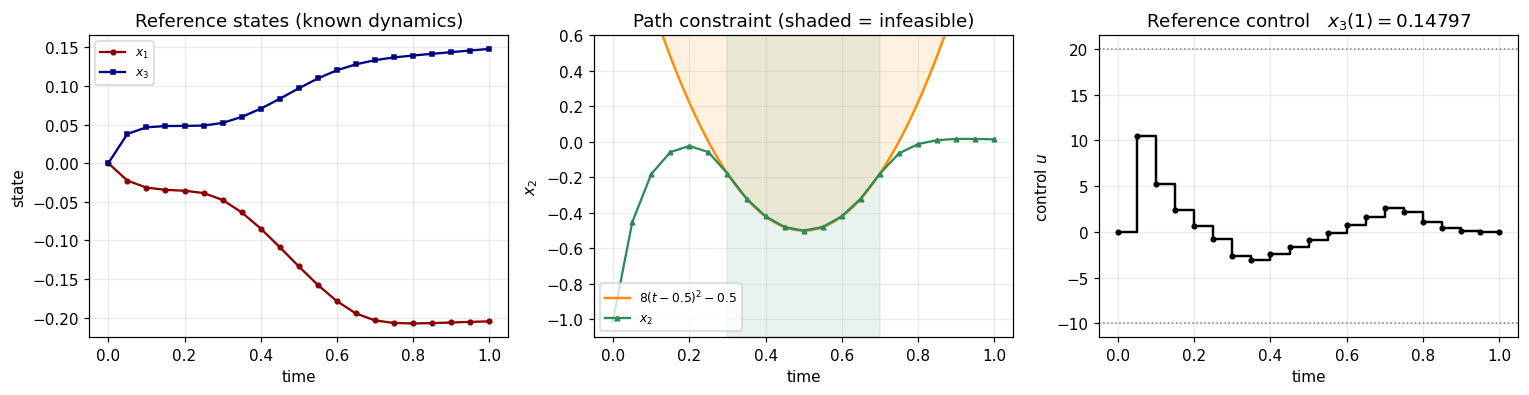

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.7))

ax[0].plot(REF["t"], REF["x1"], "-", ms=3, label=r"$x_1$", **STATE_STYLE["x1"])
ax[0].plot(REF["t"], REF["x3"], "-", ms=3, label=r"$x_3$", **STATE_STYLE["x3"])
ax[0].set_xlabel("time"); ax[0].set_ylabel("state")
ax[0].set_title("Reference states (known dynamics)")
ax[0].legend()

# x2 gets its own panel: it is the constrained state.
draw_path_bound(ax[1])
ax[1].plot(REF["t"], REF["x2"], "-", ms=3, label=r"$x_2$", **STATE_STYLE["x2"])
if REF_ARC["active pts"]:
    ax[1].axvspan(REF_ARC["arc start"], REF_ARC["arc end"],
                  color=STATE_STYLE["x2"]["color"], alpha=0.10)
ax[1].set_xlabel("time"); ax[1].set_ylabel(r"$x_2$")
ax[1].set_title("Path constraint (shaded = infeasible)")
ax[1].legend(loc="lower left")

ax[2].step(REF["t"], REF["u"], where="post", color=CONTROL_COLOR, lw=1.6)
ax[2].plot(REF["t"], REF["u"], "o", ms=3, color=CONTROL_COLOR)
ax[2].axhline(U_BOUNDS[0], **BOUND_KW)
ax[2].axhline(U_BOUNDS[1], **BOUND_KW)
ax[2].set_xlabel("time"); ax[2].set_ylabel(r"control $u$")
ax[2].set_title(f"Reference control   $x_3(1)={REF_OBJ:.5f}$")

fig.tight_layout()
plt.show()

### How much does the collocation order matter?

Before we introduce any surrogate error, we should know how much of the objective
moves purely because of the discretization. Otherwise a difference between two
formulations at different `ncp` is largely uninterpretable. This also helps us decide
when we have "enough" collocation points / finite elements.

Here there is a second reason to look: the path constraint is enforced only at the
time points, so `ncp` also sets how finely the active arc is resolved. Watch the
number of active points, not just the objective.

Each `ncp` gets its own reference objective, and that is what the surrogate results
get compared against later to make the comparisons fair.

In [9]:
ref_rows = []
REF_BY_NCP = {}

for ncp in NCP_LIST:
    mm = mechanistic_model(ncp=ncp)
    rr = SolverFactory("ipopt").solve(mm, tee=False)
    tj = trajectories(mm)
    REF_BY_NCP[ncp] = {"traj": tj, "obj": value(mm.obj)}
    ref_rows.append({
        "ncp": ncp,
        "time points": len(mm.t),
        "objective x3(1)": value(mm.obj),
        **arc_summary(tj),
        "box bounds active": ", ".join(active_box_bounds(tj)) or "none",
        "status": str(rr.solver.termination_condition),
    })

ref_df = pd.DataFrame(ref_rows)
# Difference from the next-coarser ncp (NCP_LIST is sorted ascending), i.e. how
# far the objective moves from the discretization alone. NaN for the first row.
ref_df["Δ obj vs previous ncp"] = ref_df["objective x3(1)"].diff()
print(ref_df.to_string(index=False))

 ncp  time points  objective x3(1)  active pts  arc start  arc end    min slack box bounds active  status  Δ obj vs previous ncp
   1           21         0.147970           9        0.3      0.7 2.622075e-08              none optimal                    NaN
   2           41         0.169442          17        0.3      0.7 7.753462e-09              none optimal               0.021473


---
# 2 &nbsp;&nbsp;The surrogate

Now we throw away the whole known right-hand side and learn it. The NODE is learning
the derivative of all state functions in this case study.

$$
\mathcal{N}: \; (x_1,\; x_2,\; x_3,\; u) \;\longmapsto\; (\dot x_1,\; \dot x_2,\; \dot x_3)
$$

### Sampling

The training points come from a **Latin hypercube** over the input space.

**NOTE: The sampling space is larger than the OCP space**: every state bound is
extended by $0.25$ and the control bounds by $2.5$ in both directions (for example
$x_2 \in [-1.75,\,0.75]$ vs $[-1.5,\,0.5]$, and $u \in [-12.5,\,22.5]$ vs
$[-10,\,20]$). If the optimum presses against a bound, that is where a network trained
only up to the bound starts to struggle.

Two things are specific to this case study:

* **$x_3$ is sampled even though nothing depends on it.** It is a network input, so it
  has to be varied in training; held constant, the network would learn an arbitrary
  sensitivity to it.
* **The outputs have very different scales.** $\dot x_2 = -x_2 + u$ spans roughly
  $[-13,\,24]$ over the sampling box, while $\dot x_1 = x_2$ spans about
  $[-1.75,\,0.75]$ and $\dot x_3$ about $[0,\,6]$. The unscaled MSE loss is therefore
  dominated by $\dot x_2$, so the training table below reports the RMSE of each output
  separately. $\dot x_3$ matters most: it is the only nonlinear output, and its
  integral is the objective.

Targets are the analytic derivatives, noise-free. That is a deliberate simplification:
it means any objective mismatch between formulations in Section 4 is a code/formulation
bug, not NN model error. With noisy targets it becomes difficult to tell the two apart.

In [10]:
def true_derivatives(X):
    """Analytic right-hand side.

    Reads the columns of X by name (INPUT_ORDER) and returns the outputs in
    OUTPUT_ORDER, so the labels stay correct whatever order the lists use.
    x3 is never read: the true dynamics do not depend on the accumulated cost.
    """
    v = dict(zip(INPUT_ORDER, X.T))
    rhs = {
        "dx1dt": v["x2"],
        "dx2dt": -v["x2"] + v["u"],
        "dx3dt": v["x1"] ** 2 + v["x2"] ** 2 + 0.005 * v["u"] ** 2,
    }
    return np.column_stack([rhs[nm] for nm in OUTPUT_ORDER])


def sample_lhs(n=N_SAMPLES, seed=SEED):
    """Latin hypercube over SAMPLE_BOUNDS, returned in INPUT_ORDER."""
    np.random.seed(seed)
    lo = np.array([SAMPLE_BOUNDS[nm][0] for nm in INPUT_ORDER])
    hi = np.array([SAMPLE_BOUNDS[nm][1] for nm in INPUT_ORDER])
    unit = lhs(N_IN, samples=n, criterion="maximin")
    return lo + unit * (hi - lo)


X_all = sample_lhs()
Y_all = true_derivatives(X_all)

n_train = int((1 - VAL_FRACTION) * len(X_all))
X_train, X_val = X_all[:n_train], X_all[n_train:]
Y_train, Y_val = Y_all[:n_train], Y_all[n_train:]

print(f"samples   {X_all.shape[0]}   train {len(X_train)} / val {len(X_val)}")
print(f"inputs    {INPUT_ORDER}   ranges {[SAMPLE_BOUNDS[n] for n in INPUT_ORDER]}")
print(f"outputs   {OUTPUT_ORDER}")
print()
print(pd.DataFrame(
    np.column_stack([X_all, Y_all]),
    columns=INPUT_ORDER + OUTPUT_ORDER,
).describe().loc[["min", "mean", "max"]].to_string())

samples   5000   train 4000 / val 1000
inputs    ['x1', 'x2', 'x3', 'u']   ranges [(-0.75, 0.75), (-1.75, 0.75), (-0.75, 0.75), (-12.5, 22.5)]
outputs   ['dx1dt', 'dx2dt', 'dx3dt']

            x1        x2        x3          u     dx1dt      dx2dt     dx3dt
min  -0.749844 -1.749579 -0.749818 -12.496270 -1.749579 -13.149308  0.004897
mean  0.000001 -0.500002 -0.000001   4.999974 -0.500002   5.499976  1.593750
max   0.749943  0.749663  0.749722  22.499110  0.749663  24.080112  5.853053


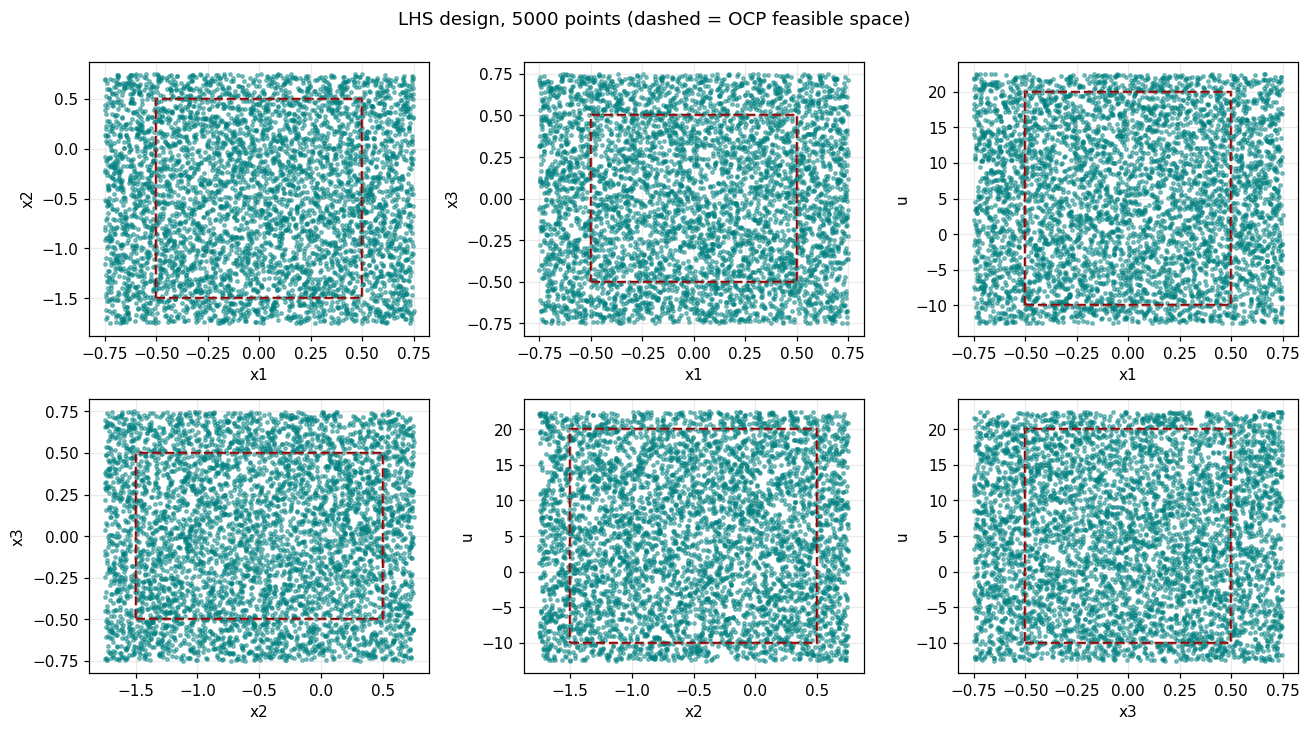

In [11]:
# Every pair of inputs, three panels per row.
pairs = list(combinations(range(N_IN), 2))
ncols = min(3, len(pairs))
nrows = int(np.ceil(len(pairs) / ncols))
fig, ax = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.3 * nrows), squeeze=False)
ax = ax.ravel()
for a, (i, j) in zip(ax, pairs):
    ni, nj = INPUT_ORDER[i], INPUT_ORDER[j]
    a.scatter(X_all[:, i], X_all[:, j], s=5, alpha=0.45, color=DATA_COLOR)
    a.set_xlabel(ni); a.set_ylabel(nj)
    # Show the OCP feasible space inside the (wider) sampling space.
    (xlo, xhi), (ylo, yhi) = VAR_BOUNDS[ni], VAR_BOUNDS[nj]
    a.add_patch(plt.Rectangle((xlo, ylo), xhi - xlo, yhi - ylo,
                              fill=False, ec=ACCENT_COLOR, lw=1.6, ls="--"))
for a in ax[len(pairs):]:
    a.set_visible(False)
fig.suptitle(f"LHS design, {N_SAMPLES} points (dashed = OCP feasible space)", y=1.0)
fig.tight_layout()
plt.show()

### Training, and saving

We train two networks with identical architecture and data, differing only in the
hidden activation. That is the point: the activation alone decides *which
formulations are even available* in Section 3.

A practical note on saving: A `.keras` file records the exact layer config of the
Keras version that wrote it, and newer versions add keys (`quantization_config`, for
one) that older versions do not load. So, alongside the `.keras` file we save a plain
`.npz` of the weight arrays plus the architecture, and rebuild from that for redundancy.

In [12]:
def build_net(activation, n_hidden=N_HIDDEN):
    """Single hidden layer, linear output.

    An explicit Input layer is required: passing input_shape= to Dense is
    removed in Keras 3. Compiled here rather than in train_net so that a
    network rebuilt by load_net is also ready for evaluate().
    """
    model = k.Sequential([
        k.layers.Input(shape=(N_IN,)),
        k.layers.Dense(n_hidden, activation=activation),
        k.layers.Dense(N_OUT),
    ])
    model.compile(optimizer=k.optimizers.Adam(1e-3), loss="mean_squared_error")
    return model


def training_settings():
    """Everything (besides activation and N_HIDDEN, which are in the file
    name) that decides what a trained network is. Saved with the weights; a
    saved network is reused only if every entry still matches."""
    return {
        "input_order": list(INPUT_ORDER),
        "output_order": list(OUTPUT_ORDER),
        "sample_bounds": {nm: list(SAMPLE_BOUNDS[nm]) for nm in INPUT_ORDER},
        "n_samples": N_SAMPLES,
        "val_fraction": VAL_FRACTION,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "seed": SEED,
    }


def save_net(model, activation, n_hidden=N_HIDDEN):
    """Save both the native format and a version-proof weight archive."""
    model.save(KERAS_FMT.format(act=activation, n=n_hidden))
    arrays = {f"w{i}": w for i, w in enumerate(model.get_weights())}
    np.savez(
        WEIGHTS_FMT.format(act=activation, n=n_hidden),
        activation=activation, n_hidden=n_hidden, n_arrays=len(arrays),
        settings=json.dumps(training_settings(), sort_keys=True),
        **arrays,
    )


def load_net(activation, n_hidden=N_HIDDEN):
    """Rebuild from the .npz archive. Independent of the Keras version."""
    d = np.load(WEIGHTS_FMT.format(act=activation, n=n_hidden))
    model = build_net(d["activation"].item(), int(d["n_hidden"]))
    model.set_weights([d[f"w{i}"] for i in range(int(d["n_arrays"]))])
    return model


def cache_mismatch(activation, n_hidden=N_HIDDEN):
    """Why the saved network cannot be reused, or None if it can.

    If the notebook has been run before, the saved network is loaded to
    avoid retraining. It is only reused if it was trained with the current
    training_settings() (variable order, sampling box, sample count,
    epochs, ...). If an edit has changed any of them, this returns the names
    of what changed, and the network is retrained and resaved.
    """
    path = WEIGHTS_FMT.format(act=activation, n=n_hidden)
    if not os.path.exists(path):
        return "no saved network"
    with np.load(path) as d:
        if "settings" not in d.files:
            return "saved before training settings were recorded"
        saved = json.loads(d["settings"].item())
    now = training_settings()
    changed = [key for key in now if saved.get(key) != now[key]]
    return f"changed: {', '.join(changed)}" if changed else None


def train_net(activation, epochs=EPOCHS, batch_size=BATCH_SIZE):
    tf.keras.utils.set_random_seed(SEED)
    model = build_net(activation)
    t0 = time.perf_counter()
    hist = model.fit(X_train, Y_train, epochs=epochs, batch_size=batch_size,
                     validation_data=(X_val, Y_val), verbose=0)
    return model, hist, time.perf_counter() - t0


NETS, HISTORY, train_rows = {}, {}, []

for act in ACTIVATIONS:
    npz = WEIGHTS_FMT.format(act=act, n=N_HIDDEN)
    reason = "FORCE_RETRAIN" if FORCE_RETRAIN else cache_mismatch(act)
    if reason is None:
        NETS[act] = load_net(act)
        wall = np.nan
        print(f"{act:5s}  loaded {npz}")
    else:
        print(f"{act:5s}  retraining ({reason})")
        print(f"{act:5s}  training {EPOCHS} epochs ...", flush=True)
        NETS[act], HISTORY[act], wall = train_net(act)
        save_net(NETS[act], act)
        print(f"{act:5s}  done in {wall:.1f}s  ->  {npz}")

    P = NETS[act].predict(X_val, verbose=0)
    row = {
        "activation": act,
        "train MSE": NETS[act].evaluate(X_train, Y_train, verbose=0),
        "val MSE": NETS[act].evaluate(X_val, Y_val, verbose=0),
        "parameters": NETS[act].count_params(),
        "train time (s)": wall,
    }
    # Per-output validation RMSE: the aggregate MSE is dominated by dx2dt.
    for c, nm in enumerate(OUTPUT_ORDER):
        row[f"val RMSE {nm}"] = float(np.sqrt(np.mean((Y_val[:, c] - P[:, c]) ** 2)))
    train_rows.append(row)

print()
print(pd.DataFrame(train_rows).to_string(index=False))

tanh   retraining (changed: n_samples)
tanh   training 1500 epochs ...
tanh   done in 244.1s  ->  CS2_tutorial_tanh_50.npz
relu   retraining (changed: n_samples)
relu   training 1500 epochs ...
relu   done in 274.2s  ->  CS2_tutorial_relu_50.npz

activation  train MSE  val MSE  parameters  train time (s)  val RMSE dx1dt  val RMSE dx2dt  val RMSE dx3dt
      tanh   0.000052 0.000054         403      244.079840        0.003367        0.009543        0.007761
      relu   0.000372 0.000426         403      274.237132        0.004535        0.004949        0.035110


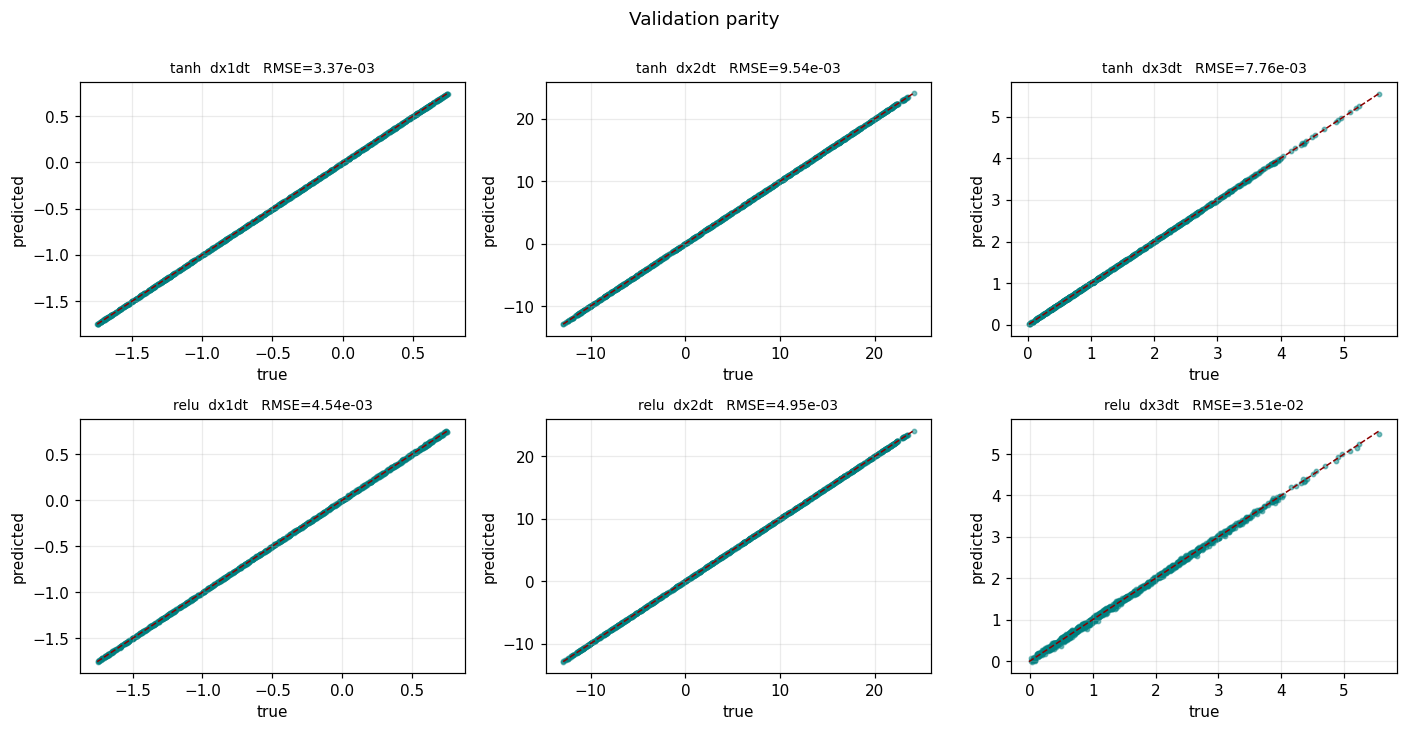

In [13]:
# Parity plots for model validation
fig, ax = plt.subplots(len(ACTIVATIONS), N_OUT,
                       figsize=(4.3 * N_OUT, 3.3 * len(ACTIVATIONS)), squeeze=False)
for r, act in enumerate(ACTIVATIONS):
    P = NETS[act].predict(X_val, verbose=0)
    for c in range(N_OUT):
        a = ax[r, c]
        a.scatter(Y_val[:, c], P[:, c], s=8, alpha=0.5, color=DATA_COLOR)
        lim = [min(Y_val[:, c].min(), P[:, c].min()),
               max(Y_val[:, c].max(), P[:, c].max())]
        a.plot(lim, lim, "--", color=ACCENT_COLOR, lw=1)
        rmse = float(np.sqrt(np.mean((Y_val[:, c] - P[:, c]) ** 2)))
        a.set_title(f"{act}  {OUTPUT_ORDER[c]}   RMSE={rmse:.2e}", fontsize=9)
        a.set_xlabel("true"); a.set_ylabel("predicted")
fig.suptitle("Validation parity", y=1.0)
fig.tight_layout()
plt.show()

Both networks fit well, but look at the per-output RMSE rather than the aggregate MSE.
The `tanh` network reaches a lower validation MSE than `relu`, and the gap is almost
entirely in $\dot x_3$, where the `relu` RMSE is several times the `tanh` one. On the
two linear outputs `relu` does as well or better, since a piecewise-linear network
represents a linear function easily. $\dot x_3 = x_1^2 + x_2^2 + 0.005u^2$ is smooth and
quadratic, so, as in CS1, piecewise-linear ReLU struggles while smooth tanh excels.

That gap matters more here than in CS1, because $\dot x_3$ is the integrand of the
objective. Near the optimal trajectory the true running cost is small (the states are
close to zero), so an error that looks minor in the parity plot is large relative to
it. A network that underpredicts the running cost there, or predicts a *negative* one,
hands the optimizer a cheaper problem than the real one, and the optimizer finds and
uses that error. Keep this in mind for Section 4: the `relu` objective lands well
below the mechanistic one, and its $x_3$ trajectory even decreases over part of the
horizon, which the true dynamics ($\dot x_3 \ge 0$) never allow. It is surrogate error,
not a bug in any of the embeddings.

---
# 3 &nbsp;&nbsp;Four ways to embed the same network

Every formulation below solves *the same optimization problem*. They differ only in
what the solver is shown.

$$
\dot x_i(t) = \mathcal{N}_i\big(x_1(t), x_2(t), x_3(t), u(t)\big),
\qquad i = 1,2,3, \qquad \forall t \in \mathcal{T}_{\text{col}}
$$

The path constraint $x_2(t) \le 8(t-0.5)^2 - 0.5$ is *not* part of any embedding. It
is written once, as ordinary Pyomo algebra, in the shared skeleton (Section 3.1), and
it is identical across all four methods.

### The design space

For a network with $H$ hidden nodes evaluated at $N$ collocation points:

| | added variables | added constraints | derivatives from | needs |
|---|---|---|---|---|
| `ECE-FS`  | $\mathcal{O}(N\,H)$ | $\mathcal{O}(N\,H)$ | AMPL AD on the algebra | any NLP solver |
| `ECE-RS`  | $\mathcal{O}(N)$ | $\mathcal{O}(N)$ | AMPL AD on nested expressions | any NLP solver |
| `ECE-CMP` | $\mathcal{O}(N\,H)$ | $\mathcal{O}(N\,H)$ | AMPL AD on the algebra | any NLP solver |
| `EFE`     | $\mathcal{O}(N)$ | $\mathcal{O}(N)$ | TensorFlow, by callback | cyipopt + PyNumero |

The trade is between problem size and what computes the derivatives.
`ECE` hands the solver an enormous but perfectly sparse, mostly-linear problem.
`EFE` hands it a smaller problem and a derivative evaluator to call.

**`ECE-RS` and `EFE` are both $\mathcal{O}(N)$, but do not have the same number of variables.**
The cause is OMLT: every OMLT formulation, full space, reduced space, or
complementarity, unconditionally builds a `scaled_inputs` / `scaled_outputs` pair
and two linking constraints per block, **even with no scaler configured**
(`omlt/formulation.py`, `_setup_scaled_inputs_outputs`; with no scaling object the
"scaling" is just the identity `scaled_inputs == inputs`, but the variables and
constraints are still real Pyomo objects). PyNumero's grey box has no such layer.
So per collocation point, with $n_{in}=4,\ n_{out}=3$:

$$
\underbrace{n_{in} + n_{out} + \overbrace{n_{in} + n_{out}}^{\text{scaled}}}_{\text{ECE-RS: 14 vars/point}}
\qquad\text{vs.}\qquad
\underbrace{n_{in} + n_{out}}_{\text{EFE: 7 vars/point}}
$$

The table above shows how each formulation *scales*; it does not say the
$\mathcal{O}(N)$ rows are numerically close, see Section 4.1's measured table.

### The support matrix

Not every activation works with every formulation.
This table is not a summary of how OMLT and PyNumero behave; it is what
happens when you build each `(formulation, activation)` pair with no
`activation_constraints` override.

| | `tanh` | `relu` |
|---|---|---|
| `ECE-FS`  | smooth NLP | big-M, introduces binaries, becomes an MINLP, not tested in this work |
| `ECE-RS`  | smooth NLP | **unsupported** (no closed-form smooth composition) |
| `ECE-CMP` | **unsupported** (ReLU-only formulation) | smooth NLP via complementarity |
| `EFE`     | smooth NLP | works, but the surrogate is not continuously differentiable, not tested in this work |

## 3.1 &nbsp;The shared skeleton

Everything except the network embedding is identical across all four methods: the same
states, bounds, objective, path constraint and collocation transformation.

Note what is *missing* compared with `mechanistic_model`: there are no `ode_x1` /
`ode_x2` / `ode_x3` constraints. Those are the holes each embedding fills. The path
constraint stays.

In [14]:
def base_ocp(nfe=NFE, ncp=NCP_REF, scheme=SCHEME):
    """The OCP with the right-hand side left out.

    Identical to mechanistic_model() minus the three ODE constraints; every
    formulation below starts from this and adds its own way of supplying
    dx1dt, dx2dt and dx3dt. The path constraint is kept, unchanged.
    """
    m = ConcreteModel()
    m.t = ContinuousSet(bounds=(0, T_FINAL))

    m.x1 = Var(m.t, initialize=VAR_INIT["x1"], bounds=VAR_BOUNDS["x1"])
    m.x2 = Var(m.t, initialize=VAR_INIT["x2"], bounds=VAR_BOUNDS["x2"])
    m.x3 = Var(m.t, initialize=VAR_INIT["x3"], bounds=VAR_BOUNDS["x3"])
    m.u = Var(m.t, initialize=VAR_INIT["u"], bounds=VAR_BOUNDS["u"])

    m.dx1dt = DerivativeVar(m.x1, wrt=m.t, initialize=0.0)
    m.dx2dt = DerivativeVar(m.x2, wrt=m.t, initialize=0.0)
    m.dx3dt = DerivativeVar(m.x3, wrt=m.t, initialize=0.0)

    m.obj = Objective(expr=m.x3[T_FINAL])

    m.path = Constraint(m.t, rule=lambda M, t: M.x2[t] <= path_bound(t))

    TransformationFactory("dae.collocation").apply_to(
        m, nfe=nfe, ncp=ncp, scheme=scheme
    )

    def _init(M):
        yield M.x1[0] == X1_0
        yield M.x2[0] == X2_0
        yield M.x3[0] == X3_0
        yield ConstraintList.End

    m.init_conditions = ConstraintList(rule=_init)

    # Every formulation builds a network copy at t=0 and links u(0) to its
    # inputs, but that copy's outputs feed nothing (t=0 has no derivative
    # equation). That pulls u(0) into the problem with no effect on the
    # objective: a degenerate, non-unique variable that IPOPT would park
    # mid-bounds. Fixing it removes the degeneracy. u(0) is therefore not an
    # optimal control value; the 0 in the control plots is this fixed value.
    m.u[0].fix(0.0)
    return m


_probe = base_ocp(ncp=NCP_REF)
print(f"skeleton at ncp={NCP_REF}:  {len(_probe.t)} time points, "
      f"{sum(1 for _ in _probe.component_data_objects(Var, active=True)):d} variables")
print(f"path constraints already present: {len(_probe.path)} (one per time point)")
print("dx1dt / dx2dt / dx3dt are currently unconstrained, each formulation fills them in.")

skeleton at ncp=1:  21 time points, 147 variables
path constraints already present: 21 (one per time point)
dx1dt / dx2dt / dx3dt are currently unconstrained, each formulation fills them in.


## 3.2 &nbsp;ECE: explicit constraint embedding with OMLT

OMLT reads the Keras model and writes the network into Pyomo as algebra. We build
**one `OmltBlock` per collocation point** and wire it to the DAE variables with
linking constraints, four in and three out per point.

### Full space (`FullSpaceNNFormulation`)

Every neuron gets variables and constraints:

$$
\hat z^{(l)} = W^{(l)} z^{(l-1)} + b^{(l)}, \qquad z^{(l)} = \sigma\big(\hat z^{(l)}\big)
$$

with $\hat z$ (pre-activation) and $z$ (post-activation) both explicit Pyomo
variables. Enormous, but every constraint is either linear or a single scalar
nonlinearity. This results in a sparse Jacobian, and the solver's linear algebra
is cheap per iteration.

### Reduced space (`ReducedSpaceNNFormulation`)

The same network as one substituted expression per output:

$$
z^{(L)} = W^{(L)}\,\sigma\big(W^{(L-1)}\sigma(\cdots) + b^{(L-1)}\big) + b^{(L)}
$$

No intermediate variables at all. A far smaller problem, but each constraint is a
deep nested expression whose gradient is dense in the inputs, and with three outputs
there are three such expressions per point instead of CS1's two.

### ReLU complementarity (`ReluComplementarityFormulation`)

$z = \max(0, \hat z)$ has no derivative at the kink, so the default full-space
handling of ReLU is **big-M with a binary per neuron**. This turns the
NLP into an MINLP. The complementarity formulation instead writes

$$
z \ge 0, \qquad z - \hat z \ge 0, \qquad z\,(z - \hat z) = 0
$$

which is smooth and continuous, so an NLP solver can attack it directly. The price
is that complementarity constraints violate the usual constraint qualifications at
the solution, and introduce nonconvexity, which is why these solves take more
iterations than their size suggests.

### Input bounds

`load_keras_sequential` takes `unscaled_input_bounds`, and OMLT propagates them through
the network to bound the hidden-layer variables (the complementarity bounds, and the
big-M coefficients). Here $u$ spans $[-10,\,20]$ while the states span intervals of
width $1$ to $2$, so the propagated bounds are loose, which is one more reason the
complementarity solves are harder than their size suggests.

In [15]:
# OMLT identifies inputs by position only, so key the bounds by the position
# each name has in INPUT_ORDER.
OMLT_INPUT_BOUNDS = {i: VAR_BOUNDS[nm] for i, nm in enumerate(INPUT_ORDER)}

ECE_FORMULATIONS = {
    "ECE-FS": FullSpaceNNFormulation,
    "ECE-RS": ReducedSpaceNNFormulation,
    "ECE-CMP": ReluComplementarityFormulation,
}


def build_ece(keras_model, formulation_name, nfe=NFE, ncp=NCP_REF):
    """One OMLT block per collocation point, linked to the DAE variables.

    Raises ValueError from OMLT if the activation is unsupported by the
    requested formulation - that is informative, so it is not caught here.
    """
    m = base_ocp(nfe, ncp)

    net = load_keras_sequential(
        keras_model, unscaled_input_bounds=OMLT_INPUT_BOUNDS
    )
    formulation = ECE_FORMULATIONS[formulation_name](net)

    m.nn = Block(m.t)
    for t in m.t:
        m.nn[t].m = OmltBlock()
        m.nn[t].m.build_formulation(formulation)

    # --- linking: DAE variables <-> network inputs ---
    # OMLT numbers its inputs 0..N_IN-1; INPUT_ORDER says which Pyomo
    # variable sits at each position.
    m.link_in = Constraint(
        m.t, range(N_IN),
        rule=lambda M, t, i: getattr(M, INPUT_ORDER[i])[t]
        == M.nn[t].m.inputs[i])

    # --- linking: network outputs -> derivatives ---
    # Skipped at t=0: dae.collocation writes no derivative equation there,
    # so dx1dt[0] is not a real degree of freedom.
    m.link_out = Constraint(
        m.t, range(N_OUT),
        rule=lambda M, t, o: Constraint.Skip if t == 0
        else getattr(M, OUTPUT_ORDER[o])[t] == M.nn[t].m.outputs[o])
    return m


print("OMLT input bounds (position -> name, bounds):")
for i, nm in enumerate(INPUT_ORDER):
    print(f"  {i}  {nm:3s}  {OMLT_INPUT_BOUNDS[i]}")

OMLT input bounds (position -> name, bounds):
  0  x1   (-0.5, 0.5)
  1  x2   (-1.5, 0.5)
  2  x3   (-0.5, 0.5)
  3  u    (-10.0, 20.0)


Let's look at what each formulation actually costs, on a *single* network block,
before any of it gets multiplied by the number of collocation points.

In [16]:
def block_size(activation, formulation_name):
    """Variables/constraints/binaries contributed by ONE OMLT block."""
    net = load_keras_sequential(NETS[activation],
                                unscaled_input_bounds=OMLT_INPUT_BOUNDS)
    blk = ConcreteModel()
    blk.m = OmltBlock()
    blk.m.build_formulation(ECE_FORMULATIONS[formulation_name](net))
    nv = sum(1 for _ in blk.component_data_objects(Var, active=True,
                                                   descend_into=True))
    nc = sum(1 for _ in blk.component_data_objects(Constraint, active=True,
                                                   descend_into=True))
    nb = sum(1 for v in blk.component_data_objects(Var, active=True,
                                                   descend_into=True)
             if v.domain is Binary)
    return nv, nc, nb


rows = []
for act in ACTIVATIONS:
    for fname in ECE_FORMULATIONS:
        try:
            nv, nc, nb = block_size(act, fname)
            rows.append({"activation": act, "formulation": fname,
                         "vars/block": nv, "cons/block": nc,
                         "binaries/block": nb, "status": "ok"})
        except Exception as exc:
            rows.append({"activation": act, "formulation": fname,
                         "vars/block": np.nan, "cons/block": np.nan,
                         "binaries/block": np.nan,
                         "status": f"{type(exc).__name__}: {exc}"})

print(f"one OMLT block, {N_IN} -> {N_HIDDEN} -> {N_OUT}\n")
print(pd.DataFrame(rows).to_string(index=False))

one OMLT block, 4 -> 50 -> 3

activation formulation  vars/block  cons/block  binaries/block                                                            status
      tanh      ECE-FS       124.0       120.0             0.0                                                                ok
      tanh      ECE-RS        14.0        10.0             0.0                                                                ok
      tanh     ECE-CMP         NaN         NaN             NaN ValueError: Activation tanh is not supported by this formulation.
      relu      ECE-FS       174.0       270.0            50.0                                                                ok
      relu      ECE-RS         NaN         NaN             NaN ValueError: Activation relu is not supported by this formulation.
      relu     ECE-CMP       174.0       220.0             0.0                                                                ok


`ECE-FS` with a **ReLU** network introduces one binary per hidden node, per
collocation point. At `ncp=2` that is $50 \times 41 = 2050$ binaries, and the problem
is no longer an NLP. It becomes an integer problem.

The tricky part is what happens next: The `.nl`
writer emits the integrality markers, IPOPT ignores them, and you get back a
converged "optimal" solution to the continuous relaxation. This is the lower bound
to the true MINLP objective, and it may not be flagged depending on settings. You would
need a solver capable of handling mixed-integer problems.

For this reason, ECE-FS with ReLU activation is omitted from this work. To extend the
work, an MINLP solver will need to be used.

## 3.3 &nbsp;EFE: external function embedding with PyNumero

Now the opposite. The network never enters the Pyomo expression tree at all.
We register **one grey-box block** covering every collocation point at once, and
IPOPT calls back into TensorFlow whenever it needs residuals or derivatives.

The block exposes only inputs and outputs, flattened point-major in
`INPUT_ORDER` / `OUTPUT_ORDER` (shown here for the default lists):

```
inputs  = [x1_0, x2_0, x3_0, u_0,   x1_1, x2_1, x3_1, u_1,   ...]     4N values
outputs = [dx1dt_0, dx2dt_0, dx3dt_0,   dx1dt_1, ...]                 3N values
```

### How this scales

The block contributes $4N$ (where N is the number of time points) input variables,
$3N$ output variables, and $3N$ output constraints, and **that is the entire cost,
whatever the network is**. Width, depth and activation change nothing: a 50-node
network and a 5000-node network hand IPOPT exactly the same NLP. Everything the network
does happens inside a callback the solver never sees. That is the structural
difference from ECE, where every hidden node becomes variables and constraints in the
model itself, and it is what Section 4.1 measures. This means that EFE scales
differently than ECE with network size.

Using one block rather than $N$ separate 4-in/3-out blocks changes nothing about the
NLP either: same variables, same constraints, same block-diagonal Jacobian sparsity.
It changes only what the callback costs. PyNumero calls back once per block, so $N$
blocks means $N$ `tf.function` dispatches at batch size 1 per solver iteration,
while one block is a single dispatch at batch size $N$: one `(N, 4)` matrix in, one
`(N, 3)` matrix out, one batched Jacobian. At this network size the arithmetic is
negligible and per-call overhead dominates, so the batched form pays that overhead
once per iteration instead of $N$ times.

### Float64

IPOPT is a double-precision code, and a float32 network's derivatives carry roughly
$10^{-6}$ error - two orders of magnitude coarser than the $10^{-8}$ tolerance the
solver is asked to meet. `to_float64` below rebuilds the network layer by layer;
Keras 3 makes the `set_floatx` shortcut unreliable, and its docstring says why.

In [17]:
def to_float64(model_f32):
    """Rebuild a Dense-only Keras model in float64 and copy the weights.

    Explicit reconstruction, not from_config under set_floatx: Keras 3 embeds
    the dtype policy in each layer config, so the floatx trick returns a
    float32 model and you get "MatMul float32 vs float64" errors later.
    """
    layers64 = []
    for lyr in model_f32.layers:
        if lyr.__class__.__name__ == "InputLayer":
            continue
        if not isinstance(lyr, k.layers.Dense):
            raise TypeError(f"only Dense layers are handled, got {type(lyr)}")
        layers64.append(k.layers.Dense(
            lyr.units, activation=lyr.get_config()["activation"],
            dtype="float64"))

    model64 = k.Sequential(layers64)
    model64.build((None, N_IN))
    model64.set_weights([w.astype(np.float64)
                         for w in model_f32.get_weights()])
    return model64


class TFEvaluator:
    """Batched value / Jacobian / Hessian for a Keras network.

    Every call handles all N collocation points at once. The tf.function
    wrappers are traced on first use; in Section 4 that cost lands in the
    first-run time (t_first_s), not in the repeated-run medians.
    """

    def __init__(self, model):
        self.model = model

        @tf.function(reduce_retracing=True)
        def _fwd(x):
            return self.model(x, training=False)

        @tf.function(reduce_retracing=True)
        def _jac(x):
            with tf.GradientTape() as tape:
                tape.watch(x)
                y = self.model(x, training=False)
            return tape.batch_jacobian(y, x)               # (N, n_out, n_in)

        @tf.function(reduce_retracing=True)
        def _hess(x, lam):
            # Second tape differentiates the lambda-weighted gradient, which
            # is exactly sum_i lam_i * d2f_i/dx2 without forming each output's
            # Hessian separately.
            with tf.GradientTape() as t2:
                t2.watch(x)
                with tf.GradientTape() as t1:
                    t1.watch(x)
                    y = self.model(x, training=False)
                g = t1.gradient(y, x, output_gradients=lam)    # (N, n_in)
            return t2.batch_jacobian(g, x)                     # (N,n_in,n_in)

        self._fwd, self._jac, self._hess = _fwd, _jac, _hess

    @staticmethod
    def _t64(a):
        return tf.constant(np.ascontiguousarray(a, dtype=np.float64),
                           dtype=tf.float64)

    def outputs(self, X):
        return np.asarray(self._fwd(self._t64(X)), dtype=np.float64)

    def jacobian(self, X):
        return np.asarray(self._jac(self._t64(X)), dtype=np.float64)

    def hessian(self, X, lam):
        return np.asarray(self._hess(self._t64(X), self._t64(lam)),
                          dtype=np.float64)


EVALUATORS = {act: TFEvaluator(to_float64(NETS[act])) for act in ACTIVATIONS}

# Sanity: batched float64 evaluation must agree with the float32 Keras model.
_probe_X = X_val[:5]
for act in ACTIVATIONS:
    d = np.abs(EVALUATORS[act].outputs(_probe_X)
               - NETS[act].predict(_probe_X, verbose=0)).max()
    print(f"{act:5s}  max |float64 - float32| on 5 points = {d:.2e}")

tanh   max |float64 - float32| on 5 points = 1.20e-06
relu   max |float64 - float32| on 5 points = 1.35e-06


### Verify the derivatives before trusting them

A wrong Jacobian sign in a grey box does not raise; it just makes IPOPT converge
somewhere wrong, or not at all. Central finite differences on the analytic
right-hand side settle the question.

In [18]:
def fd_jacobian(fn, X, h=1e-6):
    """Central-difference Jacobian of a batched function, shape (N, n_out, n_in)."""
    N = X.shape[0]
    J = np.zeros((N, N_OUT, N_IN))
    for j in range(N_IN):
        e = np.zeros(N_IN); e[j] = h
        J[:, :, j] = (fn(X + e) - fn(X - e)) / (2 * h)
    return J


def fd_hessian(fn_grad, X, lam, h=1e-6):
    """Central-difference Hessian of the lambda-weighted output."""
    N = X.shape[0]
    H = np.zeros((N, N_IN, N_IN))
    for j in range(N_IN):
        e = np.zeros(N_IN); e[j] = h
        gp = np.einsum("noi,no->ni", fn_grad(X + e), lam)
        gm = np.einsum("noi,no->ni", fn_grad(X - e), lam)
        H[:, :, j] = (gp - gm) / (2 * h)
    return H


rng = np.random.default_rng(SEED)
OCP_LO = np.array([VAR_BOUNDS[nm][0] for nm in INPUT_ORDER])
OCP_HI = np.array([VAR_BOUNDS[nm][1] for nm in INPUT_ORDER])
Xc = rng.uniform(OCP_LO, OCP_HI, size=(6, N_IN))
lam = rng.normal(size=(6, N_OUT))

print("TensorFlow AD vs central finite differences (max abs error)\n")
for act in ACTIVATIONS:
    ev = EVALUATORS[act]
    dJ = np.abs(ev.jacobian(Xc) - fd_jacobian(ev.outputs, Xc)).max()
    dH = np.abs(ev.hessian(Xc, lam) - fd_hessian(ev.jacobian, Xc, lam)).max()
    print(f"{act:5s}  jacobian {dJ:.2e}    hessian {dH:.2e}")

print()

TensorFlow AD vs central finite differences (max abs error)

tanh   jacobian 2.26e-09    hessian 4.99e-10
relu   jacobian 2.36e-09    hessian 0.00e+00



### How well did the network learn that $x_3$ does not matter?

The true Jacobian has a column of exact zeros for $x_3$. The learned one does not, and
the size of that column is the sensitivity to the accumulated cost that the network
invented. It is a property of the network, not of any formulation, so every embedding
hands it to the solver.

In [19]:
def true_jacobian(X):
    """Analytic d(OUTPUT_ORDER)/d(INPUT_ORDER), shape (N, n_out, n_in)."""
    v = dict(zip(INPUT_ORDER, X.T))
    one, zero = np.ones(len(X)), np.zeros(len(X))
    d = {   # d[output][input]; inputs not listed have zero derivative
        "dx1dt": {"x2": one},
        "dx2dt": {"x2": -one, "u": one},
        "dx3dt": {"x1": 2 * v["x1"], "x2": 2 * v["x2"], "u": 0.01 * v["u"]},
    }
    return np.stack([np.stack([d[o].get(i, zero) for i in INPUT_ORDER], axis=-1)
                     for o in OUTPUT_ORDER], axis=1)


Xs = rng.uniform(OCP_LO, OCP_HI, size=(500, N_IN))
fmt = lambda v: f"{v:8.4f}"

print("Mean |d output / d input| over 500 points in the OCP box\n")
print("--- true ---")
print(pd.DataFrame(np.abs(true_jacobian(Xs)).mean(axis=0), index=OUTPUT_ORDER,
                   columns=INPUT_ORDER).to_string(float_format=fmt))
j3 = INPUT_ORDER.index("x3")
for act in ACTIVATIONS:
    J = EVALUATORS[act].jacobian(Xs)
    print(f"\n--- {act} (learned) ---")
    print(pd.DataFrame(np.abs(J).mean(axis=0), index=OUTPUT_ORDER,
                       columns=INPUT_ORDER).to_string(float_format=fmt))
    print(f"    max |d/dx3| = {np.abs(J[:, :, j3]).max():.4f}   (true value: 0)")

Mean |d output / d input| over 500 points in the OCP box

--- true ---
            x1       x2       x3        u
dx1dt   0.0000   1.0000   0.0000   0.0000
dx2dt   0.0000   1.0000   0.0000   1.0000
dx3dt   0.5001   1.2955   0.0000   0.0825

--- tanh (learned) ---
            x1       x2       x3        u
dx1dt   0.0011   1.0008   0.0005   0.0002
dx2dt   0.0066   1.0037   0.0016   1.0006
dx3dt   0.5013   1.3061   0.0015   0.0826
    max |d/dx3| = 0.0062   (true value: 0)

--- relu (learned) ---
            x1       x2       x3        u
dx1dt   0.0025   1.0004   0.0018   0.0029
dx2dt   0.0025   1.0009   0.0021   1.0006
dx3dt   0.5147   1.3780   0.0083   0.0878
    max |d/dx3| = 0.0747   (true value: 0)


In [20]:
class NODEGreyBox(ExternalGreyBoxModel):
    """dx/dt = NN(inputs) at every collocation point, as one grey box.

    Flattened point-major in INPUT_ORDER / OUTPUT_ORDER, e.g. for the
    default lists:
        inputs  = [x1_0, x2_0, x3_0, u_0, x1_1, x2_1, x3_1, u_1, ...]
        outputs = [dx1dt_0, dx2dt_0, dx3dt_0, dx1dt_1, ...]

    Hessian-capable. PyNumero detects that purely from the existence of
    evaluate_hessian_outputs (hasattr, not a flag), which also obliges us to
    override set_output_constraint_multipliers - see the note on that method.
    """

    def __init__(self, evaluator, n_points):
        self.ev = evaluator
        self.N = int(n_points)
        self._x = np.zeros(self.N * N_IN, dtype=np.float64)
        self._lam = np.zeros(self.N * N_OUT, dtype=np.float64)

        # Constant Jacobian sparsity, built once: PyNumero caches the
        # structure and asserts it is identical on every call. Dense
        # per-point blocks, row = i*N_OUT + o, col = i*N_IN + j.
        i = np.repeat(np.arange(self.N), N_OUT * N_IN)
        o = np.tile(np.repeat(np.arange(N_OUT), N_IN), self.N)
        j = np.tile(np.arange(N_IN), self.N * N_OUT)
        self._jac_rows = i * N_OUT + o
        self._jac_cols = i * N_IN + j

        # Constant Hessian sparsity: lower-triangular dense blocks, one per
        # point. PyNumero rejects any entry with row < col.
        a, b = np.tril_indices(N_IN)
        pt = np.repeat(np.arange(self.N), a.size)
        self._h_a, self._h_b = a, b
        self._hess_rows = pt * N_IN + np.tile(a, self.N)
        self._hess_cols = pt * N_IN + np.tile(b, self.N)

    # --- naming ------------------------------------------------------
    def input_names(self):
        return [f"{nm}_{i}" for i in range(self.N) for nm in INPUT_ORDER]

    def output_names(self):
        return [f"{nm}_{i}" for i in range(self.N) for nm in OUTPUT_ORDER]

    # --- construction hook -------------------------------------------
    def finalize_block_construction(self, pyomo_block):
        """Bounds and starting values for the grey-box variables.

        Without this every grey-box input starts at 0.0 with no bounds,
        inconsistent with the DAE variables they are linked to. The outputs
        are warm-started with a forward pass so the output constraints begin
        (near) feasible.
        """
        for i in range(self.N):
            for nm in INPUT_ORDER:
                v = pyomo_block.inputs[f"{nm}_{i}"]
                v.setlb(VAR_BOUNDS[nm][0])
                v.setub(VAR_BOUNDS[nm][1])
                v.value = VAR_INIT[nm]

        x0 = np.tile([VAR_INIT[nm] for nm in INPUT_ORDER], (self.N, 1))
        y0 = self.ev.outputs(x0)
        for i in range(self.N):
            for o, nm in enumerate(OUTPUT_ORDER):
                pyomo_block.outputs[f"{nm}_{i}"].value = float(y0[i, o])

    # --- state -------------------------------------------------------
    def set_input_values(self, x):
        self._x[:] = np.asarray(x, dtype=np.float64).reshape(-1)

    def set_output_constraint_multipliers(self, lam):
        """Required override, not an optional refinement.

        The base implementation guards on a legacy attribute name that does
        not exist any more, so it returns without storing anything. Inherit
        it and evaluate_hessian_outputs below assembles from stale zeros on
        every iteration, silently.
        """
        self._lam[:] = np.asarray(lam, dtype=np.float64).reshape(-1)

    def _X(self):
        return self._x.reshape(self.N, N_IN)

    # --- evaluation --------------------------------------------------
    def evaluate_outputs(self):
        return self.ev.outputs(self._X()).reshape(-1)

    def evaluate_jacobian_outputs(self):
        J = self.ev.jacobian(self._X())                    # (N, n_out, n_in)
        return sp.coo_matrix(
            (J.reshape(-1), (self._jac_rows, self._jac_cols)),
            shape=(self.N * N_OUT, self.N * N_IN),
        )

    def evaluate_hessian_outputs(self):
        """Lower triangle of sum_o lam_o * d2(out_o)/dx2, block diagonal.

        Positive sign: PyNumero writes the residual as f(u) - o = 0, so the
        Lagrangian contribution in the inputs is lam^T f(u).
        """
        lam = self._lam.reshape(self.N, N_OUT)
        H = self.ev.hessian(self._X(), lam)                # (N, n_in, n_in)
        vals = H[:, self._h_a, self._h_b].reshape(-1)
        n = self.N * N_IN
        return sp.coo_matrix(
            (vals, (self._hess_rows, self._hess_cols)), shape=(n, n)
        )


# PyNumero decides Hessian support by hasattr, so deleting either method
# below silently downgrades the solve rather than raising.
assert hasattr(NODEGreyBox, "evaluate_hessian_outputs")
assert "set_output_constraint_multipliers" in vars(NODEGreyBox)
print("NODEGreyBox: Hessian support detected by PyNumero =",
      hasattr(NODEGreyBox, "evaluate_hessian_outputs"))

NODEGreyBox: Hessian support detected by PyNumero = True


In [21]:
def build_efe(evaluator, nfe=NFE, ncp=NCP_REF):
    """A single grey-box block covering all collocation points."""
    m = base_ocp(nfe, ncp)

    tps = sorted(m.t)
    idx = {t: i for i, t in enumerate(tps)}

    m.nn = ExternalGreyBoxBlock()
    m.nn.set_external_model(NODEGreyBox(evaluator, len(tps)))

    # --- linking: DAE variables <-> grey-box inputs (by name) ---
    m.link_in = Constraint(
        m.t, range(N_IN),
        rule=lambda M, t, i: getattr(M, INPUT_ORDER[i])[t]
        == M.nn.inputs[f"{INPUT_ORDER[i]}_{idx[t]}"])

    # --- linking: grey-box outputs -> derivatives (by name) ---
    m.link_out = Constraint(
        m.t, range(N_OUT),
        rule=lambda M, t, o: Constraint.Skip if t == 0
        else getattr(M, OUTPUT_ORDER[o])[t]
        == M.nn.outputs[f"{OUTPUT_ORDER[o]}_{idx[t]}"])
    return m


if HAVE_EFE:
    _m = build_efe(EVALUATORS["tanh"], ncp=NCP_REF)
    _gb = _m.nn.get_external_model()
    print(f"grey box at ncp={NCP_REF}: {_gb.N} points, "
          f"{len(_gb.input_names())} inputs, {len(_gb.output_names())} outputs")
    print(f"first inputs : {_gb.input_names()[:2 * N_IN]}")
    print(f"first outputs: {_gb.output_names()[:2 * N_OUT]}")

    _s = SolverFactory("cyipopt")
    _s.config.options["tol"] = TOL
    _s.config.options["print_level"] = 0
    _r = _s.solve(_m)
    print(f"\nsmoke solve: {_r.solver.termination_condition}, "
          f"objective {value(_m.obj):.8f}")
else:
    print("EFE unavailable - see the environment check at the top.")

grey box at ncp=1: 21 points, 84 inputs, 63 outputs
first inputs : ['x1_0', 'x2_0', 'x3_0', 'u_0', 'x1_1', 'x2_1', 'x3_1', 'u_1']
first outputs: ['dx1dt_0', 'dx2dt_0', 'dx3dt_0', 'dx1dt_1', 'dx2dt_1', 'dx3dt_1']

smoke solve: optimal, objective 0.15404807


In [22]:
# --- cost per time point: the OMLT blocks of Section 3.2 next to EFE ---
# One OMLT block covers one time point. The grey box covers all N points at
# once, so a one-point grey box measures what it adds per point. The linking
# constraints (N_IN + N_OUT per point) sit outside both and are left out.
def efe_size_per_point(activation):
    """Variables / constraints / binaries one time point adds to the grey box."""
    gb = NODEGreyBox(EVALUATORS[activation], n_points=1)
    n_var = len(gb.input_names()) + len(gb.output_names())
    n_con = len(gb.output_names())   # one implicit f(u) - o = 0 per output
    return n_var, n_con, 0


per_point = []
for act in ACTIVATIONS:
    for fname in ECE_FORMULATIONS:
        try:
            nv, nc, nb_ = block_size(act, fname)
        except ValueError:
            continue                  # unsupported pair, see the 3.2 table
        per_point.append({"activation": act, "formulation": fname,
                          "vars/point": nv, "cons/point": nc,
                          "binaries/point": nb_})
    nv, nc, nb_ = efe_size_per_point(act)
    per_point.append({"activation": act, "formulation": "EFE",
                      "vars/point": nv, "cons/point": nc,
                      "binaries/point": nb_})

print(f"cost per time point, {N_IN} -> {N_HIDDEN} -> {N_OUT} network\n")
print(pd.DataFrame(per_point).to_string(index=False))

cost per time point, 4 -> 50 -> 3 network

activation formulation  vars/point  cons/point  binaries/point
      tanh      ECE-FS         124         120               0
      tanh      ECE-RS          14          10               0
      tanh         EFE           7           3               0
      relu      ECE-FS         174         270              50
      relu     ECE-CMP         174         220               0
      relu         EFE           7           3               0


---
# 4 &nbsp;&nbsp;The comparison

Now we run every formulation, on both networks, across `NCP_LIST` (just `NCP_REF` when
`QUICK_TEST = True`)

* **problem size**: variables and constraints as the solver sees them
* **build time**: constructing the Pyomo model, which is *not* free for ECE
* **solve time**: median of `N_REPS` repeated solves
* **first-run time** (`t_first_s`): build + solve the first time each case runs,
  one-time costs included
* **iterations** and **seconds per iteration**: because a method that takes 10x
  longer with 10x the iterations is telling you something different from one that
  takes 10x longer per iteration
* **objective**: against the mechanistic reference at the same `ncp`
* **the recovered control trajectory, and the recovered active arc** of the path
  constraint (`active pts`, `min slack`)

### Two things that have to be right for the timings to mean anything

**First run vs repeated runs.** The first time a case runs it pays one-time costs
that later runs do not, the biggest being TensorFlow tracing the EFE evaluator's
graphs. So every case gets one first run, timed on its own as `t_first_s` (build +
solve), followed by `N_REPS` repeated runs whose medians are `t_build_s` and
`t_solve_s`. The two answer different questions: `t_first_s` is what a one-off solve
costs, the medians are what each solve costs once the method is set up. Each EFE case
gets a fresh evaluator, so its first run includes its own tracing instead of reusing
graphs traced by earlier cells.

Process-level costs (importing the packages, loading IPOPT and the PyNumero ASL
library) are paid once by earlier cells, before the sweep starts, so they appear in
none of these columns. A truly cold start would need a fresh Python process per case.

Python's garbage collector (the cyclic garbage collector) is run before every timed run
to remove unused objects from the system's memory. ECE models create a very
large number of Python objects, and without this a full collection (about 0.1–0.2 s)
lands on roughly every other run, wherever the object count happens to cross
the threshold, which makes both the medians and `t_first_s` unreliable.

**Build time separately from solve time.** ECE constructs `N` copies of the network
as Pyomo algebra; EFE constructs one grey-box block. That construction cost is part of
what the formulation costs you, but it is not solver time, so lumping them together
would misattribute it.

### On comparing `ipopt` with `cyipopt`

Both are IPOPT. The difference is the interface:

* **`ipopt`**: Pyomo writes an `.nl` file, the solver executable reads it, AMPL's
  AD library supplies derivatives.
* **`cyipopt`**: Python calls IPOPT in-process. For an ordinary Pyomo model this
  *still* goes through an `.nl` file and ASL internally, so it mostly just swaps
  the driver. For a grey-box model it is the only option, because a callback into
  TensorFlow cannot be written into an `.nl` file.

Put simply: **ECE always pays for writing and differentiating the network as algebra;
EFE moves that cost into Python/TensorFlow callbacks.** Running both solver backends on
the ECE rows is what lets you separate the two effects instead of guessing.

In [23]:
# Per-process: two kernels (or a stale one) sharing this path fight over the
# file, and an IPOPT that cannot open its output_file aborts the solve.
IPOPT_LOG = os.path.join(tempfile.gettempdir(),
                         f"cs2_ipopt_iters_{os.getpid()}.log")
ITER_RE = re.compile(r"Number of Iterations\.*:\s*(\d+)")


def solver_options():
    """Options common to both backends.

    output_file/file_print_level are how we recover the iteration count:
    neither Pyomo interface populates results.solver.statistics reliably,
    but IPOPT itself will write its log wherever we ask.
    """
    return {
        "tol": TOL,
        "max_iter": MAX_ITER,
        "print_level": 0,
        "output_file": IPOPT_LOG,
        "file_print_level": 4,
    }


def make_solver(solver_name, opts):
    """cyipopt takes options through .config.options, the .nl interface
    through .options. Assigning a whole dict to config.options silently
    drops every entry, which is a memorable way to lose max_iter and spend
    an afternoon confused."""
    s = SolverFactory(solver_name)
    target = s.config.options if solver_name == "cyipopt" else s.options
    for key, val in opts.items():
        target[key] = val
    return s


def read_iterations():
    try:
        with open(IPOPT_LOG) as fh:
            match = ITER_RE.search(fh.read())
        return int(match.group(1)) if match else np.nan
    except OSError:
        return np.nan


def problem_size(m):
    """Variables / constraints, including any grey-box block.

    ExternalGreyBoxBlock carries its own ctype, so the ordinary Var traversal
    (descend_into=True descends into Block) may or may not reach its
    inputs/outputs depending on the Pyomo version. Deduplicating by id() is
    correct either way. The block also contributes one implicit output
    constraint f(u) - o = 0 per output, which no traversal will show.
    """
    seen = {}

    def collect(container):
        for v in container.component_data_objects(Var, active=True,
                                                  descend_into=True):
            seen[id(v)] = v

    collect(m)
    n_gb_con = 0
    for blk in m.component_data_objects(ExternalGreyBoxBlock, active=True,
                                        descend_into=True):
        collect(blk)
        n_gb_con += len(blk.get_external_model().output_names())

    n_con = sum(1 for _ in m.component_data_objects(Constraint, active=True,
                                                    descend_into=True))
    return len(seen), n_con + n_gb_con


def method_label(formulation, activation):
    """Display name used in tables and plot legends, e.g. "ECE-FS (tanh)"."""
    return f"{formulation} ({activation})"


print("harness ready")

harness ready


In [24]:
def run_case(case, n_reps=N_REPS):
    """Time one first run (build + solve), then n_reps repeated runs.

    The first run carries any one-time cost this case is the first to pay
    (e.g. TF tracing) and is reported on its own as t_first_s. Every run,
    first or repeated, builds a fresh model and solves it from the same
    initial guesses. Python's garbage collector is run before every timed
    run, so a collection pause triggered by earlier runs does not land on
    whichever run happens to be next. Returns a row dict plus the trajectory
    of the last solved model.
    Unsupported combinations raise inside build(); the exception is recorded
    rather than propagated. The same applies to a solver that
    dies mid-sweep.
    """
    row = {
        "ncp": case["ncp"],
        "formulation": case["formulation"],
        "activation": case["activation"],
        "solver": case["solver"],
        "hessian": case["hessian"],
        "note": case.get("note", ""),
    }
    opts = solver_options()

    # --- first run, timed on its own: includes one-time costs ---
    try:
        gc.collect()
        t0 = time.perf_counter()
        m_first = case["build"]()
        make_solver(case["solver"], opts).solve(m_first)
        t_first = time.perf_counter() - t0
        del m_first
    except Exception as exc:
        row["status"] = f"FAILED: {type(exc).__name__}: {exc}"
        return row, None

    # --- repeated runs, each from a fresh model ---
    t_build, t_solve = [], []
    m = res = None
    try:
        for _ in range(n_reps):
            m = None              # drop the previous model, then collect
            gc.collect()
            t0 = time.perf_counter()
            m = case["build"]()
            t_build.append(time.perf_counter() - t0)

            solver = make_solver(case["solver"], opts)
            t0 = time.perf_counter()
            res = solver.solve(m)
            t_solve.append(time.perf_counter() - t0)
    except Exception as exc:
        row["status"] = f"FAILED: {type(exc).__name__}: {exc}"
        return row, None

    n_var, n_con = problem_size(m)
    iters = read_iterations()
    t_med = float(np.median(t_solve))
    traj = trajectories(m)
    arc = arc_summary(traj)

    row.update({
        "variables": n_var,
        "constraints": n_con,
        "t_build_s": round(float(np.median(t_build)), 4),
        "t_solve_s": round(t_med, 4),
        "t_solve_sd": round(float(np.std(t_solve)), 4),
        "t_first_s": round(t_first, 4),
        "iters": iters,
        "ms_per_iter": (round(1000 * t_med / iters, 3)
                        if iters and np.isfinite(iters) and iters > 0
                        else np.nan),
        "objective": round(float(value(m.obj)), 8),
        "active pts": arc["active pts"],
        "arc start": arc["arc start"],
        "arc end": arc["arc end"],
        "min slack": round(arc["min slack"], 6),
        "status": str(res.solver.termination_condition),
    })
    return row, traj


def make_cases(ncp):
    """Every (formulation, activation, solver) combination to run.

    ReLU appears only with ECE-CMP, the one formulation that requires a
    piecewise-linear activation. EFE is a smooth-NLP method and is paired
    with tanh, where the network's second derivatives exist and are nonzero.
    Every case uses exact Hessians.
    """
    cases = []

    allowed_ece = [
        ("ECE-FS", "tanh"),
        ("ECE-RS", "tanh"),
        ("ECE-CMP", "relu"),
    ]

    for fname, act in allowed_ece:
        for solver in ("ipopt", "cyipopt"):
            cases.append({
                "ncp": ncp, "formulation": fname, "activation": act,
                "solver": solver, "hessian": "exact", "note": "",
                "build": (lambda a=act, f=fname, c=ncp:
                          build_ece(NETS[a], f, ncp=c)),
            })

    if HAVE_EFE:
        # A fresh evaluator per case: its tf.functions have never been traced,
        # so this case's first run pays its own tracing rather than reusing
        # graphs traced by the checks earlier in the notebook.
        ev = TFEvaluator(to_float64(NETS["tanh"]))
        cases.append({
            "ncp": ncp, "formulation": "EFE", "activation": "tanh",
            "solver": "cyipopt", "hessian": "exact", "note": "",
            "build": (lambda c=ncp, e=ev: build_efe(e, ncp=c)),
        })

    return cases


n_cases = len(make_cases(NCP_LIST[0]))
print(f"{n_cases} cases per ncp x {len(NCP_LIST)} ncp values "
      f"= {n_cases * len(NCP_LIST)} runs")
print(f"each run = 1 first run (t_first_s) + {N_REPS} repeated runs (medians)")

7 cases per ncp x 2 ncp values = 14 runs
each run = 1 first run (t_first_s) + 5 repeated runs (medians)


This is the long cell. Most of its time goes to the ReLU complementarity cases, which
is itself part of the result.

In [25]:
results, TRAJ = [], {}
t_start = time.perf_counter()

for ncp in NCP_LIST:
    print(f"\n=== ncp = {ncp} " + "=" * 52)
    for case in make_cases(ncp):
        tag = (f"{case['formulation']:8s} {case['activation']:5s} "
               f"{case['solver']:8s} {case['hessian']:6s}")
        row, traj = run_case(case)
        results.append(row)
        if traj is not None:
            TRAJ[(ncp, case["formulation"], case["activation"],
                  case["solver"], case["hessian"])] = traj

        if row["status"].startswith("FAILED"):
            print(f"  {tag}  {row['status'][:78]}")
        else:
            print(f"  {tag}  t={row['t_solve_s']:7.3f}s  "
                  f"first={row['t_first_s']:7.3f}s  "
                  f"iters={row['iters']:>4}  obj={row['objective']:.6f}  "
                  f"arc={row['active pts']:>2} pts  "
                  f"{row['status']}")

RESULTS = pd.DataFrame(results)
print(f"\ntotal wall time {time.perf_counter() - t_start:.1f}s")


=== ncp = 1 ====================================================
  ECE-FS   tanh  ipopt    exact   t=  0.829s  first=  1.113s  iters= 160  obj=0.154048  arc= 9 pts  optimal
  ECE-FS   tanh  cyipopt  exact   t=  1.372s  first=  1.891s  iters= 103  obj=0.154048  arc= 9 pts  optimal
  ECE-RS   tanh  ipopt    exact   t=  0.152s  first=  0.213s  iters=  12  obj=0.154048  arc= 9 pts  optimal
  ECE-RS   tanh  cyipopt  exact   t=  0.164s  first=  0.215s  iters=  12  obj=0.154048  arc= 9 pts  optimal
  ECE-CMP  relu  ipopt    exact   t=  5.715s  first=  6.118s  iters= 678  obj=0.140212  arc= 9 pts  optimal
  ECE-CMP  relu  cyipopt  exact   t= 17.997s  first= 21.738s  iters= 660  obj=0.143190  arc= 9 pts  optimal
  EFE      tanh  cyipopt  exact   t=  0.116s  first=  0.344s  iters=  12  obj=0.154048  arc= 9 pts  optimal

=== ncp = 2 ====================================================
  ECE-FS   tanh  ipopt    exact   t=  0.893s  first=  1.256s  iters=  88  obj=0.175428  arc=17 pts  optimal
  EC

## 4.1 &nbsp;Solve time and problem size

Every row here is IPOPT. The `solver` column says how the problem *reached* it, and
the two routes are not interchangeable:

* **`ipopt`** writes the model to an AMPL `.nl` file and runs the `ipopt` executable
  as a subprocess. Every function and derivative evaluation happens in compiled C
  through the ASL; Python is out of the loop once the file is written.
* **`cyipopt`** links IPOPT in-process. PyNumero assembles the NLP in Python, and the
  solver calls back across the Python boundary for residuals and derivatives on every
  iteration.

EFE can only use `cyipopt`. The `.nl` format is purely algebraic and has no way to
encode "call this TensorFlow function", so a grey box exists only on the in-process
path. ECE is run on both: the two routes agreeing to eight digits is a check on the
wiring, and it supplies the `cyipopt` row that EFE can actually be compared against.

That second reason matters, because the routes differ in cost (see `ms_per_iter`).
The in-process penalty grows with problem size, since every iteration ships the full
Jacobian through Python instead of staying inside ASL. A formulation comparison drawn
from the `cyipopt` rows is like-for-like; one that mixes `.nl` ECE against in-process
EFE is partly measuring the interface.

In [26]:
ok = RESULTS[~RESULTS["status"].str.startswith("FAILED")].copy()
ok["method"] = [method_label(f, a)
                for f, a in zip(ok["formulation"], ok["activation"])]
# Only rows that converged to an optimum are evidence about where the
# optimum is; a run that hit max_iter just stopped early.
ok["trustworthy"] = ok["status"] == "optimal"

cols = ["ncp", "method", "solver", "hessian", "variables", "constraints",
        "t_build_s", "t_solve_s", "t_solve_sd", "t_first_s", "iters",
        "ms_per_iter", "objective", "active pts", "min slack", "status"]

for ncp in NCP_LIST:
    sub = ok[ok["ncp"] == ncp][cols].sort_values(["method", "solver"])
    ref = REF_BY_NCP[ncp]
    print(f"\n{'=' * 132}\nncp = {ncp}    "
          f"({NFE * ncp + 1} time points)    "
          f"mechanistic reference x3(1) = {ref['obj']:.8f}    "
          f"mechanistic arc = {arc_summary(ref['traj'])['active pts']} pts\n"
          f"{'=' * 132}")
    print(sub.to_string(index=False))

fails = RESULTS[RESULTS["status"].str.startswith("FAILED")]
if len(fails):
    print(f"\n{'=' * 132}\nUnsupported combinations (the empirical support matrix)"
          f"\n{'=' * 132}")
    seen = fails.drop_duplicates(subset=["formulation", "activation"])
    for _, r in seen.iterrows():
        print(f"  {r['formulation']:8s} + {r['activation']:5s}  ->  "
              f"{r['status'].split(': ', 1)[-1]}")


ncp = 1    (21 time points)    mechanistic reference x3(1) = 0.14796952    mechanistic arc = 9 pts
 ncp         method  solver hessian  variables  constraints  t_build_s  t_solve_s  t_solve_sd  t_first_s  iters  ms_per_iter  objective  active pts  min slack  status
   1 ECE-CMP (relu) cyipopt   exact       3801         4848     0.2648    17.9965      1.1508    21.7378    660       27.267   0.143190           9        0.0 optimal
   1 ECE-CMP (relu)   ipopt   exact       3801         4848     0.2627     5.7148      0.1093     6.1178    678        8.429   0.140212           9        0.0 optimal
   1  ECE-FS (tanh) cyipopt   exact       2751         2748     0.1723     1.3723      0.0301     1.8914    103       13.324   0.154048           9        0.0 optimal
   1  ECE-FS (tanh)   ipopt   exact       2751         2748     0.2218     0.8285      0.0380     1.1130    160        5.178   0.154048           9        0.0 optimal
   1  ECE-RS (tanh) cyipopt   exact        441          438     0

In [27]:
# Problem size does not depend on the solver backend, so one row per
# (ncp, method) is enough.
size = ok.drop_duplicates(subset=["ncp", "method"])

piv_v = size.pivot(index="ncp", columns="method", values="variables")
piv_c = size.pivot(index="ncp", columns="method", values="constraints")

print("VARIABLES\n"); print(piv_v.to_string())
print("\nCONSTRAINTS\n"); print(piv_c.to_string())

VARIABLES

method  ECE-CMP (relu)  ECE-FS (tanh)  ECE-RS (tanh)  EFE (tanh)
ncp                                                             
1                 3801           2751            441         294
2                 7421           5371            861         574

CONSTRAINTS

method  ECE-CMP (relu)  ECE-FS (tanh)  ECE-RS (tanh)  EFE (tanh)
ncp                                                             
1                 4848           2748            438         291
2                 9468           5368            858         571


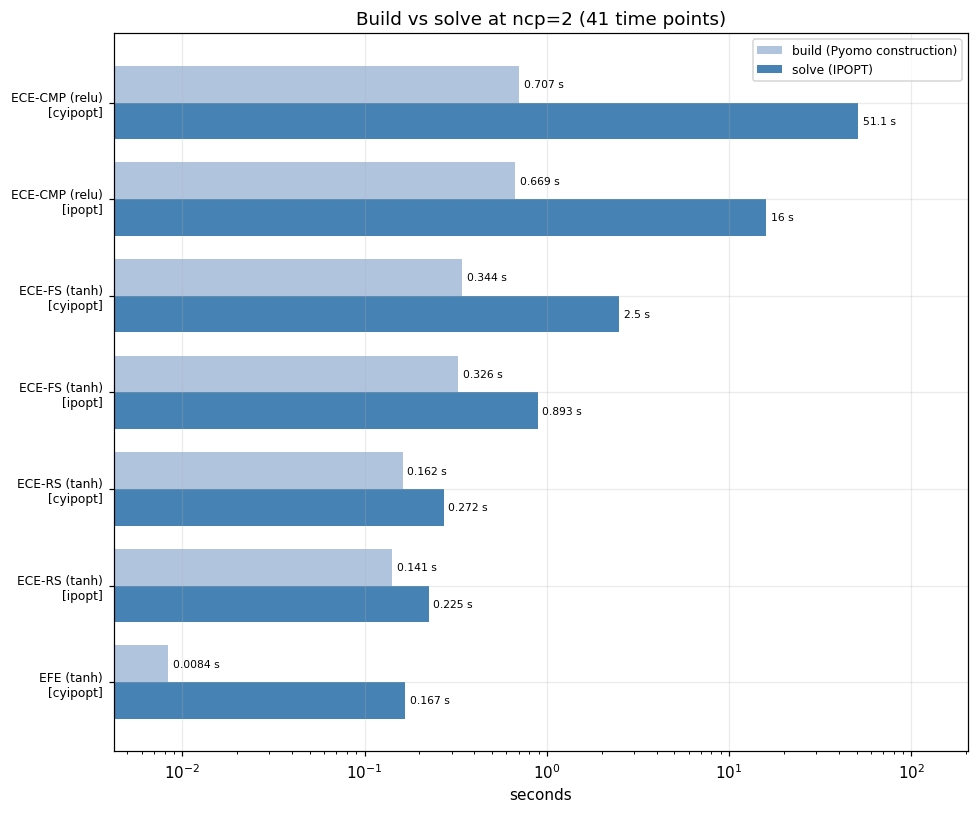

In [28]:
# --- build vs solve, at the largest ncp ---
# Every (method, solver) row, so each ECE method shows both the .nl (ipopt) and
# the in-process (cyipopt) route, and EFE is compared like-for-like with the
# cyipopt rows. Listed alphabetically from the top.
ncp_max = max(NCP_LIST)
bar = (ok[ok["ncp"] == ncp_max]
       .sort_values(["method", "solver"], ascending=False))

# Build and solve side by side, not stacked: on a log axis a stacked segment's
# length does not show its value, and a very short build (EFE) falls off the
# left edge entirely. Note t_solve_s includes Pyomo writing the model out for
# IPOPT, which is larger for the ECE formulations.
fig, ax = plt.subplots(figsize=(9, 0.9 * len(bar) + 1.2))
y = np.arange(len(bar))
h = 0.38
b_build = ax.barh(y + h / 2, bar["t_build_s"], height=h, color=BUILD_COLOR,
                  label="build (Pyomo construction)")
b_solve = ax.barh(y - h / 2, bar["t_solve_s"], height=h, color=SOLVE_COLOR,
                  label="solve (IPOPT)")
for container in (b_build, b_solve):
    ax.bar_label(container, fmt="%.3g s", padding=3, fontsize=7)
t_all = np.concatenate([bar["t_build_s"], bar["t_solve_s"]])
ax.set_xlim(t_all.min() / 2, t_all.max() * 4)   # room for the value labels
ax.set_yticks(y)
ax.set_yticklabels([f"{m}\n[{s}]" for m, s in
                    zip(bar["method"], bar["solver"])], fontsize=8)
ax.set_xlabel("seconds")
ax.set_xscale("log")
ax.set_title(f"Build vs solve at ncp={ncp_max} ({NFE * ncp_max + 1} time points)")
ax.legend()
fig.tight_layout()
fig.savefig("CS2_tutorial_build_vs_solve.png")
plt.show()

In [29]:
# --- first run vs repeated runs, next to the build/solve chart above ---
# t_first_s is the first build + solve of each case, one-time costs included.
# setup_s = t_first_s - (t_build_s + t_solve_s): what the first run cost beyond
# a typical repeated run, mostly TensorFlow tracing for EFE. Small values
# (a few hundredths of a second, either sign) are timing noise.
first = ok[["ncp", "method", "solver", "t_build_s", "t_solve_s",
            "t_first_s"]].copy()
first["build+solve_s"] = first["t_build_s"] + first["t_solve_s"]
first["setup_s"] = first["t_first_s"] - first["build+solve_s"]
first = first[["ncp", "method", "solver", "t_build_s", "t_solve_s",
               "build+solve_s", "t_first_s", "setup_s"]]

for ncp in NCP_LIST:
    sub = (first[first["ncp"] == ncp]
           .drop(columns="ncp")
           .sort_values("t_first_s")
           .round(4))
    print(f"\nncp = {ncp}   ({NFE * ncp + 1} time points)")
    print(sub.to_string(index=False))


ncp = 1   (21 time points)
        method  solver  t_build_s  t_solve_s  build+solve_s  t_first_s  setup_s
 ECE-RS (tanh)   ipopt     0.0780     0.1525         0.2305     0.2135  -0.0170
 ECE-RS (tanh) cyipopt     0.0889     0.1640         0.2529     0.2151  -0.0378
    EFE (tanh) cyipopt     0.0055     0.1164         0.1219     0.3442   0.2223
 ECE-FS (tanh)   ipopt     0.2218     0.8285         1.0503     1.1130   0.0627
 ECE-FS (tanh) cyipopt     0.1723     1.3723         1.5446     1.8914   0.3468
ECE-CMP (relu)   ipopt     0.2627     5.7148         5.9775     6.1178   0.1403
ECE-CMP (relu) cyipopt     0.2648    17.9965        18.2613    21.7378   3.4765

ncp = 2   (41 time points)
        method  solver  t_build_s  t_solve_s  build+solve_s  t_first_s  setup_s
 ECE-RS (tanh)   ipopt     0.1413     0.2250         0.3663     0.3797   0.0134
 ECE-RS (tanh) cyipopt     0.1616     0.2721         0.4337     0.3882  -0.0455
    EFE (tanh) cyipopt     0.0084     0.1670         0.1754     

## 4.2 &nbsp;Control and state trajectories

Every formulation is a different encoding of the same mathematics, so
every formulation that is wired up correctly must return the **same trajectories**,
up to surrogate error, which differs between the `tanh` and `relu`
networks but not between formulations sharing a network.

The dashed black line is the mechanistic solution at the same `ncp`. Where
formulations coincide, each later one is drawn thinner on top of the one before, so
every formulation stays visible as an outline. In the $x_2$ row the orange parabola is
the path constraint; watch where each trajectory rides it.

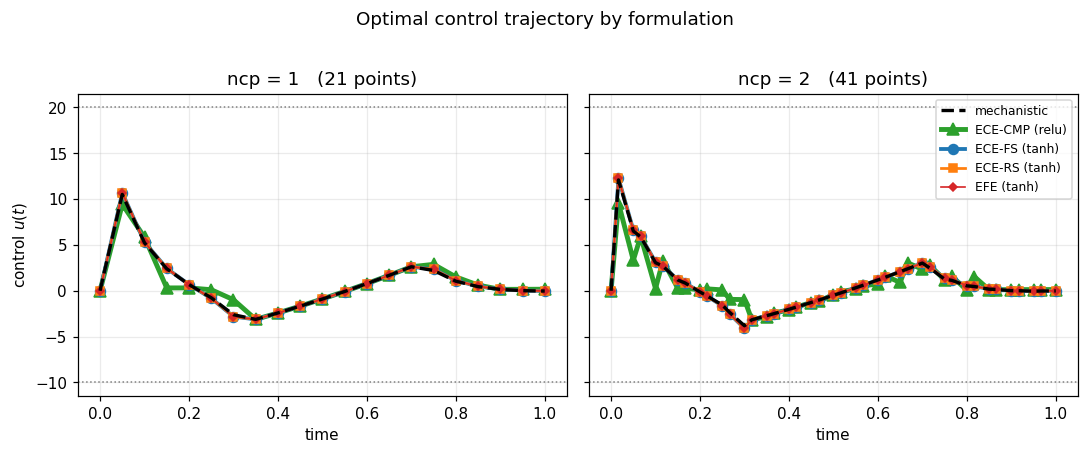

In [30]:
def representative(ncp, formulation, activation):
    """One trajectory per (formulation, activation): backends agree, so we
    only need one. Prefer the .nl backend for determinism."""
    for solver in ("ipopt", "cyipopt"):
        key = (ncp, formulation, activation, solver, "exact")
        if key in TRAJ:
            return TRAJ[key]
    return None


combos = sorted({(r["formulation"], r["activation"]) for r in results
                 if not r["status"].startswith("FAILED")})

fig, axes = plt.subplots(1, len(NCP_LIST), figsize=(5 * len(NCP_LIST), 4),
                         sharey=True)
axes = np.atleast_1d(axes)

for a, ncp in zip(axes, NCP_LIST):
    a.plot(REF_BY_NCP[ncp]["traj"]["t"], REF_BY_NCP[ncp]["traj"]["u"], **REF_KW)
    # Formulations that share a network give identical trajectories, so draw
    # each successive one thinner and smaller on top of the last (layer_kw).
    for k, (fname, act) in enumerate(combos):
        tr = representative(ncp, fname, act)
        if tr is None:
            continue
        meth = method_label(fname, act)
        a.plot(tr["t"], tr["u"], "-", label=meth,
               **method_style(meth), **layer_kw(k))
    a.axhline(U_BOUNDS[0], **BOUND_KW)
    a.axhline(U_BOUNDS[1], **BOUND_KW)
    a.set_xlabel("time")
    a.set_title(f"ncp = {ncp}   ({NFE * ncp + 1} points)")

axes[0].set_ylabel(r"control $u(t)$")
axes[-1].legend(loc="upper right")
fig.suptitle("Optimal control trajectory by formulation", y=1.02)
fig.tight_layout()
fig.savefig("CS2_tutorial_control_trajectories.png")
plt.show()

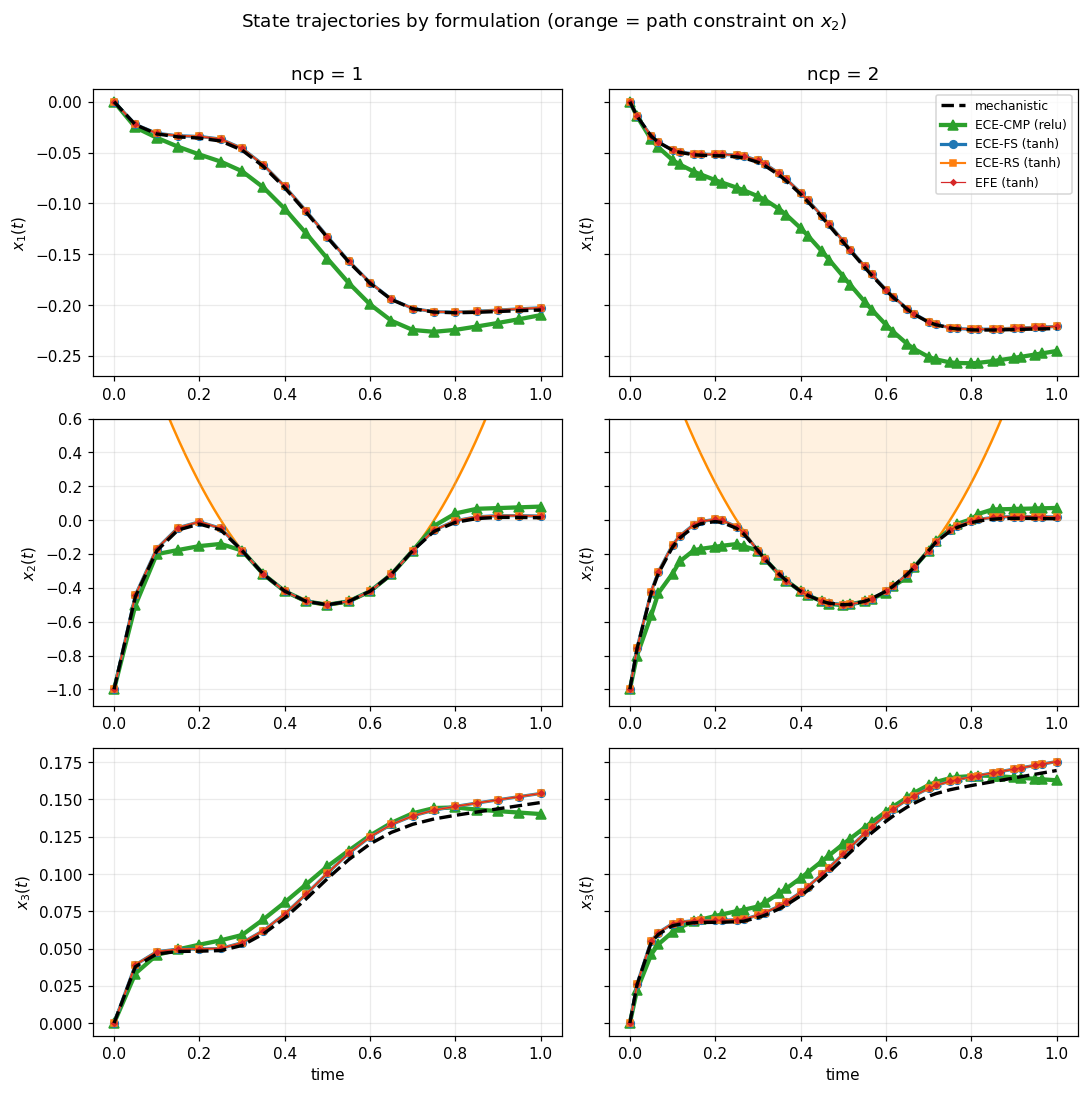

In [31]:
# squeeze=False keeps axes 2-D (n_states x n_ncp) even for a single ncp.
fig, axes = plt.subplots(len(STATE_ORDER), len(NCP_LIST),
                         figsize=(5 * len(NCP_LIST), 3.3 * len(STATE_ORDER)),
                         sharey="row", squeeze=False)

for col, ncp in enumerate(NCP_LIST):
    ref = REF_BY_NCP[ncp]["traj"]
    for r, sname in enumerate(STATE_ORDER):
        a = axes[r, col]
        if sname == "x2":
            draw_path_bound(a)          # the path constraint applies to x2 only
        a.plot(ref["t"], ref[sname], **REF_KW)
        for k, (fname, act) in enumerate(combos):
            tr = representative(ncp, fname, act)
            if tr is None:
                continue
            meth = method_label(fname, act)
            a.plot(tr["t"], tr[sname], "-", label=meth,
                   **method_style(meth), **layer_kw(k, lw0=2.8, ms0=6.5))
        a.set_ylabel(f"${sname[0]}_{sname[1]}(t)$")
        if r == 0:
            a.set_title(f"ncp = {ncp}")
        if r == len(STATE_ORDER) - 1:
            a.set_xlabel("time")

axes[0, -1].legend()
fig.suptitle("State trajectories by formulation "
             "(orange = path constraint on $x_2$)", y=1.0)
fig.tight_layout()
fig.savefig("CS2_tutorial_state_trajectories.png")
plt.show()

## 4.3 &nbsp;Do the formulations agree?

1. **Within one network, do all formulations return the same optimum?**
   They should. A nonzero spread points to a bug inside one formulation (a wrong
   grey-box derivative, a bounds or linking mistake on one path) or to two
   formulations landing in different local optima of this nonconvex problem.
   Either way it is *not* a property of the network.
2. **Does every formulation recover the same active arc?**
   Two solutions can have nearly equal objectives and still meet the path constraint
   differently, or not meet it at all. Formulations sharing a network should agree;
   a shifted or missing arc between the `tanh` and `relu` rows is surrogate error.
3. **How far is each network's optimum from the mechanistic one?**
   That gap is surrogate error, and it is the price of using a NODE at all.

In [32]:
# Only converged rows are evidence about the optimum. Including a
# maxIterations row would report a mismatch that is really just a solve
# that stopped early.
trust = ok[ok["trustworthy"]]

print("1) Agreement across formulations sharing the same network")
print("   (nonzero spread => formulation-specific bug or a different local optimum)\n")

agree = []
for (ncp, act), grp in trust.groupby(["ncp", "activation"]):
    n_form = grp["formulation"].nunique()
    spread = grp["objective"].max() - grp["objective"].min()
    if n_form < 2:
        verdict = "only 1 formulation converged - nothing to compare"
    elif spread < 1e-5:
        verdict = "OK"
    else:
        verdict = "MISMATCH - formulation bug or different local optimum"
    agree.append({
        "ncp": ncp, "activation": act,
        "formulations": n_form, "rows": len(grp),
        "objective": grp["objective"].median(),
        "spread": spread, "verdict": verdict,
    })
print(pd.DataFrame(agree).to_string(index=False))

print("\n\n2) Active set: where does each solution ride the path constraint?")
print("   Read 'min slack' with the count: 0 active points at a slack of 1e-5 is")
print("   a near miss, 0 active points at a slack of 0.1 is a different solution.\n")
arc_rows = []
for ncp in NCP_LIST:
    arc_rows.append({"ncp": ncp, "method": "mechanistic", "solver": "ipopt",
                     **arc_summary(REF_BY_NCP[ncp]["traj"])})
    for _, r in (trust[trust["ncp"] == ncp]
                 .sort_values(["method", "solver"]).iterrows()):
        arc_rows.append({"ncp": ncp, "method": r["method"], "solver": r["solver"],
                         "active pts": r["active pts"],
                         "arc start": r["arc start"], "arc end": r["arc end"],
                         "min slack": r["min slack"]})
print(pd.DataFrame(arc_rows).to_string(index=False))

print("\n\n3) Surrogate error: NODE optimum vs mechanistic optimum\n")
err = []
for (ncp, act), grp in trust.groupby(["ncp", "activation"]):
    ref_obj = REF_BY_NCP[ncp]["obj"]
    node_obj = grp["objective"].median()
    err.append({
        "ncp": ncp, "activation": act,
        "mechanistic x3(1)": round(ref_obj, 6),
        "NODE x3(1)": round(node_obj, 6),
        "abs error": round(abs(node_obj - ref_obj), 6),
        "rel error %": round(100 * abs(node_obj - ref_obj) / abs(ref_obj), 3),
    })
print(pd.DataFrame(err).to_string(index=False))

not_conv = ok[ok["status"] != "optimal"]
if len(not_conv):
    print(f"\n   ({len(not_conv)} run(s) did not converge and are excluded "
          f"above:")
    for _, r in not_conv.iterrows():
        print(f"      ncp={r['ncp']} {r['method']} [{r['solver']}, "
              f"{r['hessian']}] -> {r['status']} after {r['iters']} iters")
    print("   )")

1) Agreement across formulations sharing the same network
   (nonzero spread => formulation-specific bug or a different local optimum)

 ncp activation  formulations  rows  objective       spread                                           verdict
   1       relu             1     2   0.141701 2.977830e-03 only 1 formulation converged - nothing to compare
   1       tanh             3     5   0.154048 4.000000e-08                                                OK
   2       relu             1     2   0.164097 2.480680e-03 only 1 formulation converged - nothing to compare
   2       tanh             3     5   0.175428 3.000000e-08                                                OK


2) Active set: where does each solution ride the path constraint?
   Read 'min slack' with the count: 0 active points at a slack of 1e-5 is
   a near miss, 0 active points at a slack of 0.1 is a different solution.

 ncp         method  solver  active pts  arc start  arc end    min slack
   1    mechanistic   i

In [33]:
RESULTS.to_csv(RESULTS_CSV, index=False)
print(f"wrote {RESULTS_CSV}  ({len(RESULTS)} rows)")
for f in ("CS2_tutorial_build_vs_solve.png",
          "CS2_tutorial_control_trajectories.png",
          "CS2_tutorial_state_trajectories.png"):
    print(f"wrote {f}")

wrote CS2_formulation_comparison.csv  (14 rows)
wrote CS2_tutorial_build_vs_solve.png
wrote CS2_tutorial_control_trajectories.png
wrote CS2_tutorial_state_trajectories.png
